# Sales Forecasting & Demand Prediction Analysis

## 04 — Forecasting Data Preparation

### Objective
Prepare historical daily sales data for time-series forecasting
while preventing future-data leakage.

### Dataset
Store Item Demand Forecasting Dataset (2013–2017)

### Initial Forecasting Target
Total daily units sold across all stores and items.

### Planned Approach
1. Validate historical daily demand.
2. Split data chronologically into training and testing periods.
3. Establish a baseline forecasting model.
4. Evaluate forecasting accuracy.
5. Compare improved forecasting models.

In [1]:
import pandas as pd

# Load cleaned historical dataset
df = pd.read_csv(
    "../data/processed/sales_cleaned.csv",
    parse_dates=["date"]
)

# Aggregate sales at daily level
forecast_df = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .rename(columns={"sales": "Total_Units_Sold"})
      .sort_values("date")
      .reset_index(drop=True)
)

print("========== FORECASTING DATASET SUMMARY ==========")

print("Original Dataset Shape:", df.shape)
print("Forecast Dataset Shape:", forecast_df.shape)

print("\nFirst 5 Records:")
display(forecast_df.head())

print("\nLast 5 Records:")
display(forecast_df.tail())

print("========== SUMMARY COMPLETE ==========")

========== FORECASTING DATASET SUMMARY ==========
Original Dataset Shape: (913000, 10)
Forecast Dataset Shape: (1826, 2)

First 5 Records:


,date,Total_Units_Sold
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237



Last 5 Records:


,date,Total_Units_Sold
1821,2017-12-27,20378
1822,2017-12-28,21885
1823,2017-12-29,23535
1824,2017-12-30,24988
1825,2017-12-31,26420


========== SUMMARY COMPLETE ==========


In [2]:
print("========== FORECASTING DATA VALIDATION ==========")

print("Total Days:", len(forecast_df))

print("First Date:", forecast_df["date"].min())
print("Last Date:", forecast_df["date"].max())

print("Missing Values:")
print(forecast_df.isna().sum())

print(
    "Duplicate Dates:",
    forecast_df["date"].duplicated().sum()
)

print(
    "Dates Sorted:",
    forecast_df["date"].is_monotonic_increasing
)

print(
    "Total Units Sold:",
    forecast_df["Total_Units_Sold"].sum()
)

print(
    "Sales Total Matches Source:",
    forecast_df["Total_Units_Sold"].sum()
    == df["sales"].sum()
)

print("========== VALIDATION COMPLETE ==========")

========== FORECASTING DATA VALIDATION ==========
Total Days: 1826
First Date: 2013-01-01 00:00:00
Last Date: 2017-12-31 00:00:00
Missing Values:
date                0
Total_Units_Sold    0
dtype: int64
Duplicate Dates: 0
Dates Sorted: True
Total Units Sold: 47704512
Sales Total Matches Source: True
========== VALIDATION COMPLETE ==========


## 2. Chronological Train/Test Split

### Objective
Divide historical daily sales into training and testing
periods while preserving chronological order.

### Training Period
January 1, 2013 – December 31, 2016

### Testing Period
January 1, 2017 – December 31, 2017

### Important
The test dataset must remain unseen during model
training and model selection.

In [3]:
# Step 7.2 - Chronological Train/Test Split

import pandas as pd

# Define cutoff date
split_date = pd.Timestamp("2017-01-01")

# Training data: Before 2017
train_df = forecast_df[
    forecast_df["date"] < split_date
].copy()

# Testing data: 2017 onwards
test_df = forecast_df[
    forecast_df["date"] >= split_date
].copy()

# Reset indexes
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("========== TRAIN/TEST SPLIT SUMMARY ==========")

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

print("\nTraining Period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting Period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining Percentage:",
      round(len(train_df) / len(forecast_df) * 100, 2))

print("Testing Percentage:",
      round(len(test_df) / len(forecast_df) * 100, 2))

print("========== SPLIT COMPLETE ==========")

========== TRAIN/TEST SPLIT SUMMARY ==========
Training Shape: (1461, 2)
Testing Shape: (365, 2)

Training Period:
2013-01-01 00:00:00 to 2016-12-31 00:00:00

Testing Period:
2017-01-01 00:00:00 to 2017-12-31 00:00:00

Training Percentage: 80.01
Testing Percentage: 19.99
========== SPLIT COMPLETE ==========


In [4]:
# Step 7.2 - Train/Test Split Validation

print("========== TRAIN/TEST VALIDATION ==========")

print("Training Days:", len(train_df))
print("Testing Days:", len(test_df))

print(
    "Total Days Preserved:",
    len(train_df) + len(test_df) == len(forecast_df)
)

print(
    "No Date Overlap:",
    set(train_df["date"]).isdisjoint(set(test_df["date"]))
)

print(
    "Chronological Order Valid:",
    train_df["date"].max() < test_df["date"].min()
)

print(
    "Sales Total Preserved:",
    train_df["Total_Units_Sold"].sum()
    + test_df["Total_Units_Sold"].sum()
    == forecast_df["Total_Units_Sold"].sum()
)

print(
    "Missing Training Values:",
    train_df.isna().sum().sum()
)

print(
    "Missing Testing Values:",
    test_df.isna().sum().sum()
)

print("========== VALIDATION COMPLETE ==========")

========== TRAIN/TEST VALIDATION ==========
Training Days: 1461
Testing Days: 365
Total Days Preserved: True
No Date Overlap: True
Chronological Order Valid: True
Sales Total Preserved: True
Missing Training Values: 0
Missing Testing Values: 0
========== VALIDATION COMPLETE ==========


## 3. Baseline Forecasting Model

### 3.1 Weekly Seasonal Naive Forecast

**Objective:** Generate baseline predictions for 2017 using
only historical training data.

**Method:** Repeat the final seven daily observations
from the training period across the entire test period.

**Forecast Horizon:** 365 days.

**Data Leakage Prevention:** No actual 2017 sales
values are used to generate predictions.

In [5]:
# Step 7.3 - Weekly Seasonal Naive Baseline

import numpy as np
import pandas as pd

# Get the final 7 days of training sales
last_7_days = train_df["Total_Units_Sold"].tail(7).to_numpy()

# Repeat the weekly pattern for the entire test period
baseline_predictions = np.resize(
    last_7_days,
    len(test_df)
)

# Create forecast results dataframe
baseline_df = test_df[["date", "Total_Units_Sold"]].copy()

baseline_df["Predicted_Units"] = baseline_predictions

baseline_df = baseline_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

print("========== BASELINE FORECAST SUMMARY ==========")

print("Last 7 Training Values:", last_7_days)

print("Forecast Days:", len(baseline_df))

print("\nFirst 10 Predictions:")
display(baseline_df.head(10))

print("\nLast 10 Predictions:")
display(baseline_df.tail(10))

print("========== FORECAST COMPLETE ==========")

========== BASELINE FORECAST SUMMARY ==========
Last 7 Training Values: [25195 16831 19341 19560 21111 22296 23792]
Forecast Days: 365

First 10 Predictions:


,date,Actual_Units,Predicted_Units
0,2017-01-01,23709,25195
1,2017-01-02,15772,16831
2,2017-01-03,18650,19341
3,2017-01-04,18510,19560
4,2017-01-05,19895,21111
5,2017-01-06,20994,22296
6,2017-01-07,22591,23792
7,2017-01-08,23700,25195
8,2017-01-09,15797,16831
9,2017-01-10,18608,19341



Last 10 Predictions:


,date,Actual_Units,Predicted_Units
355,2017-12-22,23567,22296
356,2017-12-23,24763,23792
357,2017-12-24,26130,25195
358,2017-12-25,17517,16831
359,2017-12-26,20738,19341
360,2017-12-27,20378,19560
361,2017-12-28,21885,21111
362,2017-12-29,23535,22296
363,2017-12-30,24988,23792
364,2017-12-31,26420,25195


========== FORECAST COMPLETE ==========


In [6]:
# Step 7.3 - Baseline Forecast Validation

print("========== BASELINE FORECAST VALIDATION ==========")

print("Forecast Days:", len(baseline_df))

print(
    "Missing Predictions:",
    baseline_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (baseline_df["Predicted_Units"] < 0).sum()
)

print(
    "Prediction Dates Match Test:",
    baseline_df["date"].equals(test_df["date"])
)

print(
    "Weekly Pattern Repeats:",
    np.array_equal(
        baseline_predictions[7:],
        baseline_predictions[:-7]
    )
)

print(
    "First 7 Predictions Match Training:",
    np.array_equal(
        baseline_predictions[:7],
        last_7_days
    )
)

print(
    "Average Predicted Daily Demand:",
    round(baseline_df["Predicted_Units"].mean(), 2)
)

print("========== VALIDATION COMPLETE ==========")

========== BASELINE FORECAST VALIDATION ==========
Forecast Days: 365
Missing Predictions: 0
Negative Predictions: 0
Prediction Dates Match Test: True
Weekly Pattern Repeats: True
First 7 Predictions Match Training: True
Average Predicted Daily Demand: 21171.91
========== VALIDATION COMPLETE ==========


## 4. Baseline Forecast Accuracy Evaluation

### Objective
Evaluate the weekly seasonal naive forecasting model
against actual daily sales for 2017.

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

### Important
Lower error values indicate better forecast accuracy.
The test dataset is used only for evaluation.

In [7]:
# Step 7.4 - Baseline Forecast Accuracy Evaluation

import numpy as np

# Actual and predicted demand
actual = baseline_df["Actual_Units"].to_numpy()
predicted = baseline_df["Predicted_Units"].to_numpy()

# Calculate prediction errors
errors = actual - predicted
absolute_errors = np.abs(errors)

# Mean Absolute Error
mae = np.mean(absolute_errors)

# Root Mean Squared Error
rmse = np.sqrt(np.mean(errors ** 2))

# Weighted Absolute Percentage Error
wape = (
    np.sum(absolute_errors) / np.sum(np.abs(actual))
) * 100

# Additional metrics
mean_actual = np.mean(actual)
mean_predicted = np.mean(predicted)

print("========== BASELINE FORECAST ACCURACY ==========")

print("Evaluation Days:", len(actual))

print("Mean Actual Daily Demand:", round(mean_actual, 2))

print("Mean Predicted Daily Demand:", round(mean_predicted, 2))

print("MAE:", round(mae, 2))

print("RMSE:", round(rmse, 2))

print("WAPE:", round(wape, 2), "%")

print("========== EVALUATION COMPLETE ==========")

========== BASELINE FORECAST ACCURACY ==========
Evaluation Days: 365
Mean Actual Daily Demand: 29407.51
Mean Predicted Daily Demand: 21171.91
MAE: 8435.95
RMSE: 9899.24
WAPE: 28.69 %
========== EVALUATION COMPLETE ==========


In [8]:
# Step 7.4 - Evaluation Validation

print("========== FORECAST METRICS VALIDATION ==========")

print("Evaluation Days:", len(actual))

print("Actual Values Missing:", np.isnan(actual).sum())

print("Predicted Values Missing:", np.isnan(predicted).sum())

print("MAE Non-Negative:", mae >= 0)

print("RMSE Non-Negative:", rmse >= 0)

print("RMSE >= MAE:", rmse >= mae)

print("WAPE Non-Negative:", wape >= 0)

print(
    "All Metrics Finite:",
    np.isfinite([mae, rmse, wape]).all()
)

print("========== VALIDATION COMPLETE ==========")

========== FORECAST METRICS VALIDATION ==========
Evaluation Days: 365
Actual Values Missing: 0
Predicted Values Missing: 0
MAE Non-Negative: True
RMSE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
All Metrics Finite: True
========== VALIDATION COMPLETE ==========


## 5. Baseline Forecast Evaluation Summary

The weekly seasonal naive baseline was evaluated on the
365-day test period (January–December 2017).

### Results
- MAE: 8,435.95 units
- RMSE: 9,899.24 units
- WAPE: 28.69%

### Key Finding
The baseline substantially underforecasts demand because
it repeats the final week of 2016 throughout 2017 without
adjusting for annual seasonality or demand growth.

### Next Objective
Develop improved forecasting approaches and compare
their accuracy against this baseline.

In [9]:
# Step 7.5 - Save Baseline Model Evaluation Summary

from pathlib import Path
import pandas as pd

model_results = pd.DataFrame([{
    "Model": "Weekly Seasonal Naive",
    "Train_Period": "2013-2016",
    "Test_Period": "2017",
    "MAE": round(mae, 2),
    "RMSE": round(rmse, 2),
    "WAPE_Percent": round(wape, 2)
}])

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "forecast_model_comparison.csv"

model_results.to_csv(output_path, index=False)

print("========== MODEL EVALUATION SUMMARY ==========")
display(model_results)

print("\nFile saved to:", output_path.resolve())
print("Rows:", len(model_results))
print("Columns:", len(model_results.columns))
print("========== SUMMARY COMPLETE ==========")

========== MODEL EVALUATION SUMMARY ==========


,Model,Train_Period,Test_Period,MAE,RMSE,WAPE_Percent
0,Weekly Seasonal Naive,2013-2016,2017,8435.95,9899.24,28.69



File saved to: C:\Users\ANKIT TRIPATHI\Desktop\Sales-Forecasting-Demand-Prediction\reports\forecast_model_comparison.csv
Rows: 1
Columns: 6
========== SUMMARY COMPLETE ==========


## 6. Chronological Training and Validation Split

### Objective
Create separate model-training and validation periods
within the original 2013–2016 training dataset.

### Model Training Period
January 2013 – December 2015

### Validation Period
January 2016 – December 2016

### Final Test Period
January 2017 – December 2017

### Leakage Prevention
The 2017 test data will not be used for model selection
or hyperparameter tuning.

In [10]:
# Step 7.6 - Chronological Training/Validation Split

import pandas as pd

validation_start = pd.Timestamp("2016-01-01")

# Training subset: 2013-2015
model_train_df = train_df[
    train_df["date"] < validation_start
].copy().reset_index(drop=True)

# Validation subset: 2016
validation_df = train_df[
    train_df["date"] >= validation_start
].copy().reset_index(drop=True)

print("========== TRAINING / VALIDATION SUMMARY ==========")

print("Model Training Shape:", model_train_df.shape)
print("Validation Shape:", validation_df.shape)

print("\nTraining Period:")
print(
    model_train_df["date"].min(),
    "to",
    model_train_df["date"].max()
)

print("\nValidation Period:")
print(
    validation_df["date"].min(),
    "to",
    validation_df["date"].max()
)

print("========== SPLIT COMPLETE ==========")

========== TRAINING / VALIDATION SUMMARY ==========
Model Training Shape: (1095, 2)
Validation Shape: (366, 2)

Training Period:
2013-01-01 00:00:00 to 2015-12-31 00:00:00

Validation Period:
2016-01-01 00:00:00 to 2016-12-31 00:00:00
========== SPLIT COMPLETE ==========


In [11]:
# Step 7.6 - Training/Validation Validation

print("========== TRAINING / VALIDATION CHECK ==========")

print("Model Training Days:", len(model_train_df))
print("Validation Days:", len(validation_df))

print(
    "Original Training Days Preserved:",
    len(model_train_df) + len(validation_df) == len(train_df)
)

print(
    "No Date Overlap:",
    set(model_train_df["date"]).isdisjoint(
        set(validation_df["date"])
    )
)

print(
    "Chronological Order Valid:",
    model_train_df["date"].max()
    < validation_df["date"].min()
)

print(
    "Training Sales Preserved:",
    model_train_df["Total_Units_Sold"].sum()
    + validation_df["Total_Units_Sold"].sum()
    == train_df["Total_Units_Sold"].sum()
)

print(
    "No Missing Values:",
    model_train_df.isna().sum().sum() == 0
    and validation_df.isna().sum().sum() == 0
)

print("========== VALIDATION COMPLETE ==========")

========== TRAINING / VALIDATION CHECK ==========
Model Training Days: 1095
Validation Days: 366
Original Training Days Preserved: True
No Date Overlap: True
Chronological Order Valid: True
Training Sales Preserved: True
No Missing Values: True
========== VALIDATION COMPLETE ==========


## 7. Historical Weekday Average Forecasting Model

### 7.1 Calculate Training Weekday Averages

**Objective:** Calculate average daily demand for each
day of the week using only 2013–2015 training data.

**Method:** Historical weekday mean.

**Training Period:** January 2013 – December 2015.

**Validation Period:** January 2016 – December 2016.

**Leakage Prevention:** Validation and test sales are
excluded from weekday average calculations.

In [12]:
# Step 7.7.1 - Historical Weekday Average Calculation

import pandas as pd

# Create a separate training copy
weekday_train = model_train_df.copy()

# Extract day of week (Monday=0, Sunday=6)
weekday_train["Day_Of_Week"] = (
    weekday_train["date"].dt.day_of_week
)

# Calculate average demand for each weekday
weekday_averages = (
    weekday_train
    .groupby("Day_Of_Week")["Total_Units_Sold"]
    .mean()
    .reindex(range(7))
)

# Create readable summary
weekday_summary = pd.DataFrame({
    "Day": [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ],
    "Average_Daily_Demand": weekday_averages.values
})

print("========== HISTORICAL WEEKDAY AVERAGES ==========")

display(
    weekday_summary.round(2)
)

print("Training Days:", len(weekday_train))
print("Weekdays Calculated:", len(weekday_averages))

print("========== CALCULATION COMPLETE ==========")

========== HISTORICAL WEEKDAY AVERAGES ==========


,Day,Average_Daily_Demand
0,Monday,19283.19
1,Tuesday,22413.01
2,Wednesday,22448.25
3,Thursday,24035.33
4,Friday,25685.56
5,Saturday,27325.31
6,Sunday,28967.78


Training Days: 1095
Weekdays Calculated: 7
========== CALCULATION COMPLETE ==========


In [13]:
# Step 7.7.1 - Weekday Average Validation

print("========== WEEKDAY AVERAGE VALIDATION ==========")

print("Training Days:", len(weekday_train))

print("Unique Weekdays:", weekday_train["Day_Of_Week"].nunique())

print("Weekday Averages Count:", len(weekday_averages))

print("Missing Averages:", weekday_averages.isna().sum())

print(
    "All Averages Positive:",
    (weekday_averages > 0).all()
)

print(
    "Overall Training Mean:",
    round(weekday_train["Total_Units_Sold"].mean(), 2)
)

print(
    "Validation Dates Excluded:",
    weekday_train["date"].max()
    < validation_df["date"].min()
)

print(
    "Final Test Dates Excluded:",
    weekday_train["date"].max()
    < test_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== WEEKDAY AVERAGE VALIDATION ==========
Training Days: 1095
Unique Weekdays: 7
Weekday Averages Count: 7
Missing Averages: 0
All Averages Positive: True
Overall Training Mean: 24304.67
Validation Dates Excluded: True
Final Test Dates Excluded: True
========== VALIDATION COMPLETE ==========


### 7.2 Generate Historical Weekday Average Predictions

**Objective:** Forecast daily sales demand for the
2016 validation period.

**Method:** Assign each validation date the average
demand of its corresponding weekday, calculated
from 2013–2015 training data.

**Data Leakage Prevention:** Actual 2016 sales are
used only for evaluation, not for predictions.

In [14]:
# Step 7.7.2 - Generate Validation Predictions

# Create validation dataset copy
weekday_validation_df = validation_df.copy()

# Extract weekday (Monday=0, Sunday=6)
weekday_validation_df["Day_Of_Week"] = (
    weekday_validation_df["date"].dt.day_of_week
)

# Assign historical weekday averages
weekday_validation_df["Predicted_Units"] = (
    weekday_validation_df["Day_Of_Week"]
    .map(weekday_averages)
)

# Rename actual sales column
weekday_validation_df = weekday_validation_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

print("========== WEEKDAY MODEL VALIDATION FORECAST ==========")

print("Total Forecast Days:", len(weekday_validation_df))

print("\nFirst 10 Predictions:")
display(weekday_validation_df.head(10))

print("\nLast 10 Predictions:")
display(weekday_validation_df.tail(10))

print("========== FORECAST COMPLETE ==========")

========== WEEKDAY MODEL VALIDATION FORECAST ==========
Total Forecast Days: 366

First 10 Predictions:


,date,Actual_Units,Day_Of_Week,Predicted_Units
0,2016-01-01,20158,4,25685.557692
1,2016-01-02,21280,5,27325.307692
2,2016-01-03,22911,6,28967.782051
3,2016-01-04,15199,0,19283.192308
4,2016-01-05,17806,1,22413.006369
5,2016-01-06,17789,2,22448.254777
6,2016-01-07,19107,3,24035.331210
7,2016-01-08,20265,4,25685.557692
8,2016-01-09,21309,5,27325.307692
9,2016-01-10,22811,6,28967.782051



Last 10 Predictions:


,date,Actual_Units,Day_Of_Week,Predicted_Units
356,2016-12-22,21408,3,24035.331210
357,2016-12-23,22549,4,25685.557692
358,2016-12-24,24187,5,27325.307692
359,2016-12-25,25195,6,28967.782051
360,2016-12-26,16831,0,19283.192308
361,2016-12-27,19341,1,22413.006369
362,2016-12-28,19560,2,22448.254777
363,2016-12-29,21111,3,24035.331210
364,2016-12-30,22296,4,25685.557692
365,2016-12-31,23792,5,27325.307692


========== FORECAST COMPLETE ==========


In [15]:
# Step 7.7.2 - Prediction Validation

import numpy as np

print("========== WEEKDAY FORECAST VALIDATION ==========")

print("Forecast Days:", len(weekday_validation_df))

print(
    "Missing Predictions:",
    weekday_validation_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (weekday_validation_df["Predicted_Units"] < 0).sum()
)

print(
    "Prediction Dates Match Validation:",
    weekday_validation_df["date"].equals(
        validation_df["date"]
    )
)

print(
    "Weekday Predictions Match Historical Averages:",
    np.allclose(
        weekday_validation_df["Predicted_Units"],
        weekday_validation_df["Day_Of_Week"].map(
            weekday_averages
        )
    )
)

print(
    "Unique Predicted Values:",
    weekday_validation_df["Predicted_Units"].nunique()
)

print(
    "Average Predicted Daily Demand:",
    round(
        weekday_validation_df["Predicted_Units"].mean(),
        2
    )
)

print("========== VALIDATION COMPLETE ==========")

========== WEEKDAY FORECAST VALIDATION ==========
Forecast Days: 366
Missing Predictions: 0
Negative Predictions: 0
Prediction Dates Match Validation: True
Weekday Predictions Match Historical Averages: True
Unique Predicted Values: 7
Average Predicted Daily Demand: 24320.35
========== VALIDATION COMPLETE ==========


### 7.3 Historical Weekday Average Model Evaluation

**Objective:** Evaluate the forecasting performance
of the Historical Weekday Average Model.

**Validation Period:** January–December 2016

**Metrics:**
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

**Leakage Prevention:** Model predictions use only
2013–2015 training data. Actual 2016 sales are used
only to calculate evaluation metrics.

In [16]:
# Step 7.7.3 - Historical Weekday Model Evaluation

import numpy as np

# Actual and predicted validation demand
weekday_actual = weekday_validation_df[
    "Actual_Units"
].to_numpy()

weekday_predicted = weekday_validation_df[
    "Predicted_Units"
].to_numpy()

# Calculate forecast errors
weekday_errors = weekday_actual - weekday_predicted

weekday_absolute_errors = np.abs(weekday_errors)

# Mean Absolute Error
weekday_mae = np.mean(weekday_absolute_errors)

# Root Mean Squared Error
weekday_rmse = np.sqrt(
    np.mean(weekday_errors ** 2)
)

# Weighted Absolute Percentage Error
weekday_wape = (
    np.sum(weekday_absolute_errors)
    / np.sum(np.abs(weekday_actual))
) * 100

print("========== WEEKDAY MODEL ACCURACY ==========")

print("Evaluation Days:", len(weekday_actual))

print(
    "Mean Actual Daily Demand:",
    round(np.mean(weekday_actual), 2)
)

print(
    "Mean Predicted Daily Demand:",
    round(np.mean(weekday_predicted), 2)
)

print("MAE:", round(weekday_mae, 2))

print("RMSE:", round(weekday_rmse, 2))

print("WAPE:", round(weekday_wape, 2), "%")

print("========== EVALUATION COMPLETE ==========")

========== WEEKDAY MODEL ACCURACY ==========
Evaluation Days: 366
Mean Actual Daily Demand: 28298.25
Mean Predicted Daily Demand: 24320.35
MAE: 5832.55
RMSE: 6595.17
WAPE: 20.61 %
========== EVALUATION COMPLETE ==========


In [17]:
# Step 7.7.3 - Evaluation Validation

print("========== WEEKDAY MODEL METRICS VALIDATION ==========")

print("Evaluation Days:", len(weekday_actual))

print(
    "Missing Actual Values:",
    np.isnan(weekday_actual).sum()
)

print(
    "Missing Predicted Values:",
    np.isnan(weekday_predicted).sum()
)

print("MAE Non-Negative:", weekday_mae >= 0)

print("RMSE Non-Negative:", weekday_rmse >= 0)

print("RMSE >= MAE:", weekday_rmse >= weekday_mae)

print("WAPE Non-Negative:", weekday_wape >= 0)

print(
    "All Metrics Finite:",
    np.isfinite([
        weekday_mae,
        weekday_rmse,
        weekday_wape
    ]).all()
)

print("========== VALIDATION COMPLETE ==========")

========== WEEKDAY MODEL METRICS VALIDATION ==========
Evaluation Days: 366
Missing Actual Values: 0
Missing Predicted Values: 0
MAE Non-Negative: True
RMSE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
All Metrics Finite: True
========== VALIDATION COMPLETE ==========


### 7.4 Fair Model Comparison on 2016 Validation Data

**Objective:** Compare the Weekly Seasonal Naive and
Historical Weekday Average models on identical data.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Forecast Horizon:** 366 days

**Evaluation Metrics:** MAE, RMSE, WAPE

Both models use only training-period information
to generate their validation forecasts.

In [18]:
# Step 7.7.4 - Seasonal Naive Validation Forecast

import numpy as np
import pandas as pd

# Last 7 days from 2013-2015 training data
validation_last_7 = (
    model_train_df["Total_Units_Sold"]
    .tail(7)
    .to_numpy()
)

# Repeat weekly pattern throughout 2016
seasonal_validation_predictions = np.resize(
    validation_last_7,
    len(validation_df)
)

seasonal_validation_df = validation_df[
    ["date", "Total_Units_Sold"]
].copy()

seasonal_validation_df["Predicted_Units"] = (
    seasonal_validation_predictions
)

seasonal_validation_df = seasonal_validation_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

print("========== SEASONAL BASELINE VALIDATION ==========")

print("Last 7 Training Values:", validation_last_7)

print("Forecast Days:", len(seasonal_validation_df))

print("First 7 Predictions:")
display(seasonal_validation_df.head(7))

print("========== FORECAST COMPLETE ==========")

========== SEASONAL BASELINE VALIDATION ==========
Last 7 Training Values: [20877 22256 23268 15569 18403 18191 19377]
Forecast Days: 366
First 7 Predictions:


,date,Actual_Units,Predicted_Units
0,2016-01-01,20158,20877
1,2016-01-02,21280,22256
2,2016-01-03,22911,23268
3,2016-01-04,15199,15569
4,2016-01-05,17806,18403
5,2016-01-06,17789,18191
6,2016-01-07,19107,19377


========== FORECAST COMPLETE ==========


In [19]:
# Step 7.7.4 - Fair Model Comparison

seasonal_actual = seasonal_validation_df[
    "Actual_Units"
].to_numpy()

seasonal_predicted = seasonal_validation_df[
    "Predicted_Units"
].to_numpy()

seasonal_errors = seasonal_actual - seasonal_predicted

seasonal_mae = np.mean(np.abs(seasonal_errors))

seasonal_rmse = np.sqrt(
    np.mean(seasonal_errors ** 2)
)

seasonal_wape = (
    np.sum(np.abs(seasonal_errors))
    / np.sum(np.abs(seasonal_actual))
) * 100

# Compare both models on the same validation period
validation_comparison = pd.DataFrame([
    {
        "Model": "Weekly Seasonal Naive",
        "MAE": round(seasonal_mae, 2),
        "RMSE": round(seasonal_rmse, 2),
        "WAPE_Percent": round(seasonal_wape, 2)
    },
    {
        "Model": "Historical Weekday Average",
        "MAE": round(weekday_mae, 2),
        "RMSE": round(weekday_rmse, 2),
        "WAPE_Percent": round(weekday_wape, 2)
    }
])

validation_comparison = validation_comparison.sort_values(
    "WAPE_Percent"
).reset_index(drop=True)

print("========== FAIR MODEL COMPARISON ==========")

display(validation_comparison)

print(
    "Best Model by WAPE:",
    validation_comparison.loc[0, "Model"]
)

print("========== COMPARISON COMPLETE ==========")

========== FAIR MODEL COMPARISON ==========


,Model,MAE,RMSE,WAPE_Percent
0,Historical Weekday Average,5832.55,6595.17,20.61
1,Weekly Seasonal Naive,8668.16,10110.70,30.63


Best Model by WAPE: Historical Weekday Average
========== COMPARISON COMPLETE ==========


In [20]:
# Step 7.7.4 - Comparison Validation

print("========== MODEL COMPARISON VALIDATION ==========")

print(
    "Same Evaluation Days:",
    len(seasonal_actual) == len(weekday_actual) == 366
)

print(
    "Same Actual Sales:",
    np.array_equal(seasonal_actual, weekday_actual)
)

print(
    "Dates Match:",
    seasonal_validation_df["date"].equals(
        weekday_validation_df["date"]
    )
)

print(
    "No Missing Seasonal Predictions:",
    np.isnan(seasonal_predicted).sum() == 0
)

print(
    "Weekly Pattern Repeats:",
    np.array_equal(
        seasonal_predicted[7:],
        seasonal_predicted[:-7]
    )
)

print(
    "Two Models Compared:",
    len(validation_comparison) == 2
)

print("========== VALIDATION COMPLETE ==========")

========== MODEL COMPARISON VALIDATION ==========
Same Evaluation Days: True
Same Actual Sales: True
Dates Match: True
No Missing Seasonal Predictions: True
Weekly Pattern Repeats: True
Two Models Compared: True
========== VALIDATION COMPLETE ==========


## 8. Monthly Seasonal Average Forecasting Model

### 8.1 Calculate Historical Monthly Averages

**Objective:** Identify monthly demand patterns using
only the 2013–2015 training dataset.

**Method:** Calculate average daily units sold for
each calendar month (January to December).

**Training Period:** 2013–2015

**Validation Period:** 2016

**Leakage Prevention:** Validation and test sales are
excluded from monthly average calculations.

In [21]:
# Step 7.8.1 - Historical Monthly Average Calculation

import pandas as pd

# Use only 2013-2015 training data
monthly_train = model_train_df.copy()

# Extract calendar month
monthly_train["Month"] = monthly_train["date"].dt.month

# Calculate average DAILY demand for each month
monthly_averages = (
    monthly_train
    .groupby("Month")["Total_Units_Sold"]
    .mean()
    .reindex(range(1, 13))
)

# Create readable summary
monthly_summary = pd.DataFrame({
    "Month": [
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ],
    "Average_Daily_Demand": monthly_averages.values
})

print("========== HISTORICAL MONTHLY AVERAGES ==========")

display(monthly_summary.round(2))

print("Training Days:", len(monthly_train))
print("Months Calculated:", len(monthly_averages))

print(
    "Highest Demand Month:",
    monthly_summary.loc[
        monthly_summary["Average_Daily_Demand"].idxmax(),
        "Month"
    ]
)

print(
    "Lowest Demand Month:",
    monthly_summary.loc[
        monthly_summary["Average_Daily_Demand"].idxmin(),
        "Month"
    ]
)

print("========== CALCULATION COMPLETE ==========")

========== HISTORICAL MONTHLY AVERAGES ==========


,Month,Average_Daily_Demand
0,January,16488.22
1,February,18331.56
2,March,22071.33
3,April,25507.28
4,May,27666.89
5,June,29329.14
6,July,30992.28
7,August,27664.06
8,September,25537.37
9,October,23792.72


Training Days: 1095
Months Calculated: 12
Highest Demand Month: July
Lowest Demand Month: January
========== CALCULATION COMPLETE ==========


In [22]:
# Step 7.8.1 - Monthly Average Validation

print("========== MONTHLY AVERAGE VALIDATION ==========")

print("Training Days:", len(monthly_train))

print("Unique Months:", monthly_train["Month"].nunique())

print("Monthly Averages Count:", len(monthly_averages))

print("Missing Averages:", monthly_averages.isna().sum())

print(
    "All Averages Positive:",
    (monthly_averages > 0).all()
)

print(
    "Training Mean:",
    round(monthly_train["Total_Units_Sold"].mean(), 2)
)

print(
    "Validation Dates Excluded:",
    monthly_train["date"].max()
    < validation_df["date"].min()
)

print(
    "Final Test Dates Excluded:",
    monthly_train["date"].max()
    < test_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY AVERAGE VALIDATION ==========
Training Days: 1095
Unique Months: 12
Monthly Averages Count: 12
Missing Averages: 0
All Averages Positive: True
Training Mean: 24304.67
Validation Dates Excluded: True
Final Test Dates Excluded: True
========== VALIDATION COMPLETE ==========


### 8.2 Generate Monthly Seasonal Predictions

**Objective:** Predict daily demand for the 2016 validation
period using historical calendar-month averages.

**Method:** Assign each validation date the average daily
demand of its corresponding month from 2013–2015.

**Validation Period:** January–December 2016

**Leakage Prevention:** No actual 2016 or 2017 sales values
are used to generate predictions.

In [23]:
# Step 7.8.2 - Generate Monthly Seasonal Predictions

# Create validation dataset copy
monthly_validation_df = validation_df.copy()

# Extract calendar month
monthly_validation_df["Month"] = (
    monthly_validation_df["date"].dt.month
)

# Map historical monthly averages to validation dates
monthly_validation_df["Predicted_Units"] = (
    monthly_validation_df["Month"].map(monthly_averages)
)

# Rename actual demand column
monthly_validation_df = monthly_validation_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

print("========== MONTHLY MODEL VALIDATION FORECAST ==========")

print("Total Forecast Days:", len(monthly_validation_df))

print("\nFirst 10 Predictions:")
display(monthly_validation_df.head(10))

print("\nLast 10 Predictions:")
display(monthly_validation_df.tail(10))

print("========== FORECAST COMPLETE ==========")

========== MONTHLY MODEL VALIDATION FORECAST ==========
Total Forecast Days: 366

First 10 Predictions:


,date,Actual_Units,Month,Predicted_Units
0,2016-01-01,20158,1,16488.215054
1,2016-01-02,21280,1,16488.215054
2,2016-01-03,22911,1,16488.215054
3,2016-01-04,15199,1,16488.215054
4,2016-01-05,17806,1,16488.215054
5,2016-01-06,17789,1,16488.215054
6,2016-01-07,19107,1,16488.215054
7,2016-01-08,20265,1,16488.215054
8,2016-01-09,21309,1,16488.215054
9,2016-01-10,22811,1,16488.215054



Last 10 Predictions:


,date,Actual_Units,Month,Predicted_Units
356,2016-12-22,21408,12,18195.989247
357,2016-12-23,22549,12,18195.989247
358,2016-12-24,24187,12,18195.989247
359,2016-12-25,25195,12,18195.989247
360,2016-12-26,16831,12,18195.989247
361,2016-12-27,19341,12,18195.989247
362,2016-12-28,19560,12,18195.989247
363,2016-12-29,21111,12,18195.989247
364,2016-12-30,22296,12,18195.989247
365,2016-12-31,23792,12,18195.989247


========== FORECAST COMPLETE ==========


In [24]:
# Step 7.8.2 - Monthly Forecast Validation

import numpy as np

print("========== MONTHLY FORECAST VALIDATION ==========")

print("Forecast Days:", len(monthly_validation_df))

print(
    "Missing Predictions:",
    monthly_validation_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (monthly_validation_df["Predicted_Units"] < 0).sum()
)

print(
    "Prediction Dates Match Validation:",
    monthly_validation_df["date"].equals(
        validation_df["date"]
    )
)

print(
    "Monthly Predictions Match Historical Averages:",
    np.allclose(
        monthly_validation_df["Predicted_Units"],
        monthly_validation_df["Month"].map(
            monthly_averages
        )
    )
)

print(
    "Unique Predicted Values:",
    monthly_validation_df["Predicted_Units"].nunique()
)

print(
    "Average Predicted Daily Demand:",
    round(
        monthly_validation_df["Predicted_Units"].mean(),
        2
    )
)

print(
    "First January Prediction Correct:",
    np.isclose(
        monthly_validation_df.loc[0, "Predicted_Units"],
        monthly_averages.loc[1]
    )
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY FORECAST VALIDATION ==========
Forecast Days: 366
Missing Predictions: 0
Negative Predictions: 0
Prediction Dates Match Validation: True
Monthly Predictions Match Historical Averages: True
Unique Predicted Values: 12
Average Predicted Daily Demand: 24288.35
First January Prediction Correct: True
========== VALIDATION COMPLETE ==========


### 8.3 Monthly Seasonal Model Accuracy Evaluation

**Objective:** Evaluate the Monthly Seasonal Average Model
using actual daily demand from the 2016 validation period.

**Evaluation Metrics:**
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

**Comparison:** All three models are evaluated using the
same 2016 validation period.

In [25]:
# Step 7.8.3 - Monthly Model Accuracy Evaluation

import numpy as np

monthly_actual = monthly_validation_df[
    "Actual_Units"
].to_numpy()

monthly_predicted = monthly_validation_df[
    "Predicted_Units"
].to_numpy()

# Calculate errors
monthly_errors = monthly_actual - monthly_predicted
monthly_absolute_errors = np.abs(monthly_errors)

# Calculate accuracy metrics
monthly_mae = np.mean(monthly_absolute_errors)

monthly_rmse = np.sqrt(
    np.mean(monthly_errors ** 2)
)

monthly_wape = (
    np.sum(monthly_absolute_errors)
    / np.sum(np.abs(monthly_actual))
) * 100

print("========== MONTHLY MODEL ACCURACY ==========")

print("Evaluation Days:", len(monthly_actual))

print(
    "Mean Actual Daily Demand:",
    round(np.mean(monthly_actual), 2)
)

print(
    "Mean Predicted Daily Demand:",
    round(np.mean(monthly_predicted), 2)
)

print("MAE:", round(monthly_mae, 2))
print("RMSE:", round(monthly_rmse, 2))
print("WAPE:", round(monthly_wape, 2), "%")

print("========== EVALUATION COMPLETE ==========")

========== MONTHLY MODEL ACCURACY ==========
Evaluation Days: 366
Mean Actual Daily Demand: 28298.25
Mean Predicted Daily Demand: 24288.35
MAE: 4541.68
RMSE: 5422.42
WAPE: 16.05 %
========== EVALUATION COMPLETE ==========


In [26]:
# Step 7.8.3 - Three Model Comparison

import pandas as pd

three_model_comparison = pd.DataFrame([
    {
        "Model": "Weekly Seasonal Naive",
        "MAE": round(seasonal_mae, 2),
        "RMSE": round(seasonal_rmse, 2),
        "WAPE_Percent": round(seasonal_wape, 2)
    },
    {
        "Model": "Historical Weekday Average",
        "MAE": round(weekday_mae, 2),
        "RMSE": round(weekday_rmse, 2),
        "WAPE_Percent": round(weekday_wape, 2)
    },
    {
        "Model": "Monthly Seasonal Average",
        "MAE": round(monthly_mae, 2),
        "RMSE": round(monthly_rmse, 2),
        "WAPE_Percent": round(monthly_wape, 2)
    }
])

three_model_comparison = (
    three_model_comparison
    .sort_values("WAPE_Percent")
    .reset_index(drop=True)
)

print("========== THREE MODEL COMPARISON ==========")

display(three_model_comparison)

print(
    "Best Model by WAPE:",
    three_model_comparison.loc[0, "Model"]
)

print("========== COMPARISON COMPLETE ==========")

========== THREE MODEL COMPARISON ==========


,Model,MAE,RMSE,WAPE_Percent
0,Monthly Seasonal Average,4541.68,5422.42,16.05
1,Historical Weekday Average,5832.55,6595.17,20.61
2,Weekly Seasonal Naive,8668.16,10110.70,30.63


Best Model by WAPE: Monthly Seasonal Average
========== COMPARISON COMPLETE ==========


In [27]:
# Step 7.8.3 - Monthly Model Validation

print("========== MONTHLY MODEL METRICS VALIDATION ==========")

print("Evaluation Days:", len(monthly_actual))

print(
    "Same Actual Sales as Weekday Model:",
    np.array_equal(monthly_actual, weekday_actual)
)

print(
    "Same Actual Sales as Seasonal Baseline:",
    np.array_equal(monthly_actual, seasonal_actual)
)

print(
    "Missing Actual Values:",
    np.isnan(monthly_actual).sum()
)

print(
    "Missing Predicted Values:",
    np.isnan(monthly_predicted).sum()
)

print("MAE Non-Negative:", monthly_mae >= 0)
print("RMSE >= MAE:", monthly_rmse >= monthly_mae)
print("WAPE Non-Negative:", monthly_wape >= 0)

print(
    "All Metrics Finite:",
    np.isfinite([
        monthly_mae,
        monthly_rmse,
        monthly_wape
    ]).all()
)

print(
    "Three Models Compared:",
    len(three_model_comparison) == 3
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY MODEL METRICS VALIDATION ==========
Evaluation Days: 366
Same Actual Sales as Weekday Model: True
Same Actual Sales as Seasonal Baseline: True
Missing Actual Values: 0
Missing Predicted Values: 0
MAE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
All Metrics Finite: True
Three Models Compared: True
========== VALIDATION COMPLETE ==========


## 9. Combined Month-Weekday Seasonal Forecasting Model

### 9.1 Calculate Historical Month-Weekday Averages

**Objective:** Capture both annual monthly seasonality
and weekly demand patterns.

**Method:** Calculate average daily demand for each
combination of calendar month and weekday.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Expected Combinations:** 12 months × 7 weekdays = 84

**Leakage Prevention:** Only training-period sales are
used to calculate historical averages.

In [28]:
# Step 7.9.1 - Month-Weekday Historical Averages

import pandas as pd

# Use only 2013-2015 training data
combined_train = model_train_df.copy()

# Extract calendar features
combined_train["Month"] = combined_train["date"].dt.month

combined_train["Day_Of_Week"] = (
    combined_train["date"].dt.day_of_week
)

# Calculate historical demand for each combination
combined_averages = (
    combined_train
    .groupby(["Month", "Day_Of_Week"])["Total_Units_Sold"]
    .mean()
)

# Create readable summary
combined_summary = (
    combined_averages
    .reset_index(name="Average_Daily_Demand")
)

print("========== MONTH-WEEKDAY AVERAGES ==========")

print("Training Days:", len(combined_train))

print("Total Combinations:", len(combined_averages))

print("\nFirst 15 Combinations:")
display(combined_summary.head(15).round(2))

print("\nLast 10 Combinations:")
display(combined_summary.tail(10).round(2))

print("========== CALCULATION COMPLETE ==========")

========== MONTH-WEEKDAY AVERAGES ==========
Training Days: 1095
Total Combinations: 84

First 15 Combinations:


,Month,Day_Of_Week,Average_Daily_Demand
0,1,0,13112.25
1,1,1,15116.08
2,1,2,15144.36
3,1,3,16332.80
4,1,4,17563.29
5,1,5,18572.85
6,1,6,19600.17
7,2,0,14502.33
8,2,1,16939.42
9,2,2,16957.92



Last 10 Combinations:


,Month,Day_Of_Week,Average_Daily_Demand
74,11,4,26937.54
75,11,5,28645.64
76,11,6,30691.64
77,12,0,14454.07
78,12,1,16954.33
79,12,2,17084.14
80,12,3,18216.92
81,12,4,19317.00
82,12,5,20594.67
83,12,6,21585.92


========== CALCULATION COMPLETE ==========


In [29]:
# Step 7.9.1 - Combined Model Validation

print("========== COMBINED AVERAGES VALIDATION ==========")

print("Training Days:", len(combined_train))

print("Unique Months:", combined_train["Month"].nunique())

print(
    "Unique Weekdays:",
    combined_train["Day_Of_Week"].nunique()
)

print("Total Combinations:", len(combined_averages))

print("Missing Averages:", combined_averages.isna().sum())

print(
    "All Averages Positive:",
    (combined_averages > 0).all()
)

print(
    "No Duplicate Combinations:",
    not combined_summary[
        ["Month", "Day_Of_Week"]
    ].duplicated().any()
)

print(
    "Validation Dates Excluded:",
    combined_train["date"].max()
    < validation_df["date"].min()
)

print(
    "Final Test Dates Excluded:",
    combined_train["date"].max()
    < test_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== COMBINED AVERAGES VALIDATION ==========
Training Days: 1095
Unique Months: 12
Unique Weekdays: 7
Total Combinations: 84
Missing Averages: 0
All Averages Positive: True
No Duplicate Combinations: True
Validation Dates Excluded: True
Final Test Dates Excluded: True
========== VALIDATION COMPLETE ==========


### 9.2 Generate Month-Weekday Seasonal Predictions

**Objective:** Generate daily sales forecasts for 2016
using historical month-weekday demand patterns.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Method:** Map each validation date to its corresponding
historical month-weekday average.

**Leakage Prevention:** Only training-period averages are
used to generate predictions.

In [30]:
# Step 7.9.2 - Combined Model Validation Predictions

import pandas as pd

# Create a copy of 2016 validation data
combined_validation_df = validation_df.copy()

# Extract calendar features
combined_validation_df["Month"] = (
    combined_validation_df["date"].dt.month
)

combined_validation_df["Day_Of_Week"] = (
    combined_validation_df["date"].dt.day_of_week
)

# Create month-weekday index for matching
validation_keys = pd.MultiIndex.from_frame(
    combined_validation_df[["Month", "Day_Of_Week"]]
)

# Map historical averages to validation dates
combined_validation_df["Predicted_Units"] = (
    combined_averages.reindex(validation_keys).to_numpy()
)

# Rename actual sales column
combined_validation_df = combined_validation_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

print("========== COMBINED MODEL VALIDATION FORECAST ==========")

print("Total Forecast Days:", len(combined_validation_df))

print("\nFirst 10 Predictions:")
display(combined_validation_df.head(10))

print("\nLast 10 Predictions:")
display(combined_validation_df.tail(10))

print("========== FORECAST COMPLETE ==========")

========== COMBINED MODEL VALIDATION FORECAST ==========
Total Forecast Days: 366

First 10 Predictions:


,date,Actual_Units,Month,Day_Of_Week,Predicted_Units
0,2016-01-01,20158,1,4,17563.285714
1,2016-01-02,21280,1,5,18572.846154
2,2016-01-03,22911,1,6,19600.166667
3,2016-01-04,15199,1,0,13112.250000
4,2016-01-05,17806,1,1,15116.076923
5,2016-01-06,17789,1,2,15144.357143
6,2016-01-07,19107,1,3,16332.800000
7,2016-01-08,20265,1,4,17563.285714
8,2016-01-09,21309,1,5,18572.846154
9,2016-01-10,22811,1,6,19600.166667



Last 10 Predictions:


,date,Actual_Units,Month,Day_Of_Week,Predicted_Units
356,2016-12-22,21408,12,3,18216.923077
357,2016-12-23,22549,12,4,19317.000000
358,2016-12-24,24187,12,5,20594.666667
359,2016-12-25,25195,12,6,21585.923077
360,2016-12-26,16831,12,0,14454.071429
361,2016-12-27,19341,12,1,16954.333333
362,2016-12-28,19560,12,2,17084.142857
363,2016-12-29,21111,12,3,18216.923077
364,2016-12-30,22296,12,4,19317.000000
365,2016-12-31,23792,12,5,20594.666667


========== FORECAST COMPLETE ==========


In [31]:
# Step 7.9.2 - Combined Forecast Validation

import numpy as np

print("========== COMBINED FORECAST VALIDATION ==========")

print("Forecast Days:", len(combined_validation_df))

print(
    "Missing Predictions:",
    combined_validation_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (combined_validation_df["Predicted_Units"] < 0).sum()
)

print(
    "Prediction Dates Match Validation:",
    combined_validation_df["date"].equals(
        validation_df["date"]
    )
)

print(
    "Predictions Match Historical Averages:",
    np.allclose(
        combined_validation_df["Predicted_Units"].to_numpy(),
        combined_averages.reindex(validation_keys).to_numpy()
    )
)

print(
    "Unique Month-Weekday Combinations:",
    combined_validation_df[
        ["Month", "Day_Of_Week"]
    ].drop_duplicates().shape[0]
)

print(
    "First Prediction Correct:",
    np.isclose(
        combined_validation_df.loc[0, "Predicted_Units"],
        combined_averages.loc[(1, 4)]
    )
)

print(
    "Average Predicted Daily Demand:",
    round(
        combined_validation_df["Predicted_Units"].mean(),
        2
    )
)

print("========== VALIDATION COMPLETE ==========")

========== COMBINED FORECAST VALIDATION ==========
Forecast Days: 366
Missing Predictions: 0
Negative Predictions: 0
Prediction Dates Match Validation: True
Predictions Match Historical Averages: True
Unique Month-Weekday Combinations: 84
First Prediction Correct: True
Average Predicted Daily Demand: 24299.52
========== VALIDATION COMPLETE ==========


### 9.3 Combined Month-Weekday Model Accuracy Evaluation

**Objective:** Evaluate the Combined Month-Weekday Seasonal
Average Model using actual 2016 daily sales.

**Metrics:**
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

**Comparison:** Compare all four forecasting models
on the same 2016 validation period.

**Data Leakage Prevention:** Only 2013–2015 sales are
used to generate model predictions.

In [32]:
# Step 7.9.3 - Combined Model Accuracy Evaluation

import numpy as np

combined_actual = combined_validation_df[
    "Actual_Units"
].to_numpy()

combined_predicted = combined_validation_df[
    "Predicted_Units"
].to_numpy()

# Calculate forecast errors
combined_errors = combined_actual - combined_predicted
combined_absolute_errors = np.abs(combined_errors)

# Accuracy metrics
combined_mae = np.mean(combined_absolute_errors)

combined_rmse = np.sqrt(
    np.mean(combined_errors ** 2)
)

combined_wape = (
    np.sum(combined_absolute_errors)
    / np.sum(np.abs(combined_actual))
) * 100

print("========== COMBINED MODEL ACCURACY ==========")

print("Evaluation Days:", len(combined_actual))

print(
    "Mean Actual Daily Demand:",
    round(np.mean(combined_actual), 2)
)

print(
    "Mean Predicted Daily Demand:",
    round(np.mean(combined_predicted), 2)
)

print("MAE:", round(combined_mae, 2))

print("RMSE:", round(combined_rmse, 2))

print("WAPE:", round(combined_wape, 2), "%")

print("========== EVALUATION COMPLETE ==========")

========== COMBINED MODEL ACCURACY ==========
Evaluation Days: 366
Mean Actual Daily Demand: 28298.25
Mean Predicted Daily Demand: 24299.52
MAE: 3998.73
RMSE: 4100.38
WAPE: 14.13 %
========== EVALUATION COMPLETE ==========


In [33]:
# Step 7.9.3 - Four Model Comparison

import pandas as pd

four_model_comparison = pd.DataFrame([
    {
        "Model": "Weekly Seasonal Naive",
        "MAE": round(seasonal_mae, 2),
        "RMSE": round(seasonal_rmse, 2),
        "WAPE_Percent": round(seasonal_wape, 2)
    },
    {
        "Model": "Historical Weekday Average",
        "MAE": round(weekday_mae, 2),
        "RMSE": round(weekday_rmse, 2),
        "WAPE_Percent": round(weekday_wape, 2)
    },
    {
        "Model": "Monthly Seasonal Average",
        "MAE": round(monthly_mae, 2),
        "RMSE": round(monthly_rmse, 2),
        "WAPE_Percent": round(monthly_wape, 2)
    },
    {
        "Model": "Combined Month-Weekday Average",
        "MAE": round(combined_mae, 2),
        "RMSE": round(combined_rmse, 2),
        "WAPE_Percent": round(combined_wape, 2)
    }
])

four_model_comparison = (
    four_model_comparison
    .sort_values("WAPE_Percent")
    .reset_index(drop=True)
)

print("========== FOUR MODEL COMPARISON ==========")

display(four_model_comparison)

print(
    "Best Model by WAPE:",
    four_model_comparison.loc[0, "Model"]
)

print("========== COMPARISON COMPLETE ==========")

========== FOUR MODEL COMPARISON ==========


,Model,MAE,RMSE,WAPE_Percent
0,Combined Month-Weekday Average,3998.73,4100.38,14.13
1,Monthly Seasonal Average,4541.68,5422.42,16.05
2,Historical Weekday Average,5832.55,6595.17,20.61
3,Weekly Seasonal Naive,8668.16,10110.70,30.63


Best Model by WAPE: Combined Month-Weekday Average
========== COMPARISON COMPLETE ==========


In [34]:
# Step 7.9.3 - Combined Model Metrics Validation

print("========== COMBINED MODEL METRICS VALIDATION ==========")

print("Evaluation Days:", len(combined_actual))

print(
    "Same Actual Sales as Monthly Model:",
    np.array_equal(combined_actual, monthly_actual)
)

print(
    "Same Actual Sales as Weekday Model:",
    np.array_equal(combined_actual, weekday_actual)
)

print(
    "Same Actual Sales as Seasonal Baseline:",
    np.array_equal(combined_actual, seasonal_actual)
)

print(
    "Missing Actual Values:",
    np.isnan(combined_actual).sum()
)

print(
    "Missing Predicted Values:",
    np.isnan(combined_predicted).sum()
)

print("MAE Non-Negative:", combined_mae >= 0)

print("RMSE >= MAE:", combined_rmse >= combined_mae)

print("WAPE Non-Negative:", combined_wape >= 0)

print(
    "All Metrics Finite:",
    np.isfinite([
        combined_mae,
        combined_rmse,
        combined_wape
    ]).all()
)

print(
    "Four Models Compared:",
    len(four_model_comparison) == 4
)

print("========== VALIDATION COMPLETE ==========")

========== COMBINED MODEL METRICS VALIDATION ==========
Evaluation Days: 366
Same Actual Sales as Monthly Model: True
Same Actual Sales as Weekday Model: True
Same Actual Sales as Seasonal Baseline: True
Missing Actual Values: 0
Missing Predicted Values: 0
MAE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
All Metrics Finite: True
Four Models Compared: True
========== VALIDATION COMPLETE ==========


## 10. Trend-Adjusted Seasonal Forecasting Model

### 10.1 Historical Yearly Demand Growth Analysis

**Objective:** Analyze historical sales growth using
only the 2013–2015 model-training dataset.

**Method:** Calculate annual total demand and
year-over-year growth rates.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Leakage Prevention:** No 2016 or 2017 sales data
is used to estimate historical growth.

In [35]:
# Step 7.10.1 - Historical Yearly Growth Analysis

import pandas as pd

# Use only 2013-2015 training data
trend_train = model_train_df.copy()

# Extract year
trend_train["Year"] = trend_train["date"].dt.year

# Calculate yearly demand
yearly_growth = (
    trend_train
    .groupby("Year")["Total_Units_Sold"]
    .sum()
    .reset_index(name="Total_Annual_Units")
)

# Calculate year-over-year growth
yearly_growth["YoY_Growth_Percent"] = (
    yearly_growth["Total_Annual_Units"]
    .pct_change() * 100
)

print("========== HISTORICAL YEARLY GROWTH ==========")

display(yearly_growth.round(2))

print("\nAverage Annual Growth Rate:")

average_growth_rate = (
    yearly_growth["YoY_Growth_Percent"].dropna().mean()
)

print(round(average_growth_rate, 2), "%")

print("========== GROWTH ANALYSIS COMPLETE ==========")

========== HISTORICAL YEARLY GROWTH ==========


,Year,Total_Annual_Units,YoY_Growth_Percent
0,2013,7941243,NaN
1,2014,9135482,15.04
2,2015,9536887,4.39



Average Annual Growth Rate:
9.72 %
========== GROWTH ANALYSIS COMPLETE ==========


In [36]:
# Step 7.10.1 - Growth Analysis Validation

import numpy as np

print("========== YEARLY GROWTH VALIDATION ==========")

print("Training Days:", len(trend_train))

print("Unique Years:", trend_train["Year"].nunique())

print("Yearly Records:", len(yearly_growth))

print(
    "Annual Sales Total Preserved:",
    yearly_growth["Total_Annual_Units"].sum()
    == model_train_df["Total_Units_Sold"].sum()
)

print(
    "First Year Growth Missing:",
    pd.isna(yearly_growth.loc[0, "YoY_Growth_Percent"])
)

print(
    "Valid Growth Rates:",
    yearly_growth["YoY_Growth_Percent"].notna().sum()
)

print(
    "Average Growth Finite:",
    np.isfinite(average_growth_rate)
)

print(
    "Validation Dates Excluded:",
    trend_train["date"].max()
    < validation_df["date"].min()
)

print(
    "Final Test Dates Excluded:",
    trend_train["date"].max()
    < test_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== YEARLY GROWTH VALIDATION ==========
Training Days: 1095
Unique Years: 3
Yearly Records: 3
Annual Sales Total Preserved: True
First Year Growth Missing: True
Valid Growth Rates: 2
Average Growth Finite: True
Validation Dates Excluded: True
Final Test Dates Excluded: True
========== VALIDATION COMPLETE ==========


### 10.2 Generate Trend-Adjusted Seasonal Predictions

**Objective:** Incorporate historical annual sales growth
into the Combined Month-Weekday Seasonal Forecast.

**Training Period:** 2013–2015
**Validation Period:** 2016

**Method:** Apply a historical growth adjustment to
the existing seasonal predictions.

**Leakage Prevention:** Use only training-period
information to calculate the adjustment.

In [38]:
# Step 7.10.2 - Trend-Adjusted Seasonal Predictions

import numpy as np

# Convert historical growth percentage into a multiplier
annual_growth_factor = 1 + (average_growth_rate / 100)

# Approximate midpoint of historical training period
reference_year = 2014

# Validation forecast year
forecast_year = 2016

# Number of years for trend adjustment
years_forward = forecast_year - reference_year

# Calculate trend adjustment
trend_adjustment_factor = annual_growth_factor ** years_forward

# Copy existing combined model predictions
trend_validation_df = combined_validation_df.copy()

# Apply growth adjustment
trend_validation_df["Predicted_Units"] = (
    combined_validation_df["Predicted_Units"]
    * trend_adjustment_factor
)

print("========== TREND-ADJUSTED FORECAST ==========")

print(
    "Historical Annual Growth:",
    round(average_growth_rate, 2), "%"
)

print("Reference Year:", reference_year)
print("Forecast Year:", forecast_year)
print("Years Forward:", years_forward)

print(
    "Trend Adjustment Factor:",
    round(trend_adjustment_factor, 4)
)

print("Forecast Days:", len(trend_validation_df))

print("\nFirst 10 Predictions:")
display(
    trend_validation_df.head(10).style.format(
        {"Predicted_Units": "{:.2f}"}
    )
)

print("\nLast 10 Predictions:")
display(
    trend_validation_df.tail(10).style.format(
        {"Predicted_Units": "{:.2f}"}
    )
)
print(
    "Average Predicted Daily Demand:",
    round(trend_validation_df["Predicted_Units"].mean(), 2)
)

print("========== FORECAST COMPLETE ==========")

========== TREND-ADJUSTED FORECAST ==========
Historical Annual Growth: 9.72 %
Reference Year: 2014
Forecast Year: 2016
Years Forward: 2
Trend Adjustment Factor: 1.2038
Forecast Days: 366

First 10 Predictions:


,date,Actual_Units,Month,Day_Of_Week,Predicted_Units
0,2016-01-01 00:00:00,20158,1,4,21142.05
1,2016-01-02 00:00:00,21280,1,5,22357.32
2,2016-01-03 00:00:00,22911,1,6,23593.97
3,2016-01-04 00:00:00,15199,1,0,15784.05
4,2016-01-05 00:00:00,17806,1,1,18196.19
5,2016-01-06 00:00:00,17789,1,2,18230.23
6,2016-01-07 00:00:00,19107,1,3,19660.84
7,2016-01-08 00:00:00,20265,1,4,21142.05
8,2016-01-09 00:00:00,21309,1,5,22357.32
9,2016-01-10 00:00:00,22811,1,6,23593.97



Last 10 Predictions:


,date,Actual_Units,Month,Day_Of_Week,Predicted_Units
356,2016-12-22 00:00:00,21408,12,3,21928.87
357,2016-12-23 00:00:00,22549,12,4,23253.11
358,2016-12-24 00:00:00,24187,12,5,24791.12
359,2016-12-25 00:00:00,25195,12,6,25984.36
360,2016-12-26 00:00:00,16831,12,0,17399.29
361,2016-12-27 00:00:00,19341,12,1,20409.01
362,2016-12-28 00:00:00,19560,12,2,20565.27
363,2016-12-29 00:00:00,21111,12,3,21928.87
364,2016-12-30 00:00:00,22296,12,4,23253.11
365,2016-12-31 00:00:00,23792,12,5,24791.12


Average Predicted Daily Demand: 29250.89
========== FORECAST COMPLETE ==========


In [39]:
# Step 7.10.2 - Trend Forecast Validation

import numpy as np

print("========== TREND FORECAST VALIDATION ==========")

print("Forecast Days:", len(trend_validation_df))

print(
    "Missing Predictions:",
    trend_validation_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (trend_validation_df["Predicted_Units"] < 0).sum()
)

print(
    "Prediction Dates Match Validation:",
    trend_validation_df["date"].equals(validation_df["date"])
)

print(
    "Actual Sales Unchanged:",
    np.array_equal(
        trend_validation_df["Actual_Units"].to_numpy(),
        combined_validation_df["Actual_Units"].to_numpy()
    )
)

print(
    "Growth Adjustment Correct:",
    np.allclose(
        trend_validation_df["Predicted_Units"].to_numpy(),
        combined_validation_df["Predicted_Units"].to_numpy()
        * trend_adjustment_factor
    )
)

print(
    "Adjustment Factor Finite:",
    np.isfinite(trend_adjustment_factor)
)

print(
    "All Predictions Finite:",
    np.isfinite(
        trend_validation_df["Predicted_Units"].to_numpy()
    ).all()
)

print(
    "Training Ends Before Validation:",
    model_train_df["date"].max()
    < validation_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== TREND FORECAST VALIDATION ==========
Forecast Days: 366
Missing Predictions: 0
Negative Predictions: 0
Prediction Dates Match Validation: True
Actual Sales Unchanged: True
Growth Adjustment Correct: True
Adjustment Factor Finite: True
All Predictions Finite: True
Training Ends Before Validation: True
========== VALIDATION COMPLETE ==========


### 10.3 Trend-Adjusted Seasonal Model Accuracy Evaluation

**Objective:** Evaluate the Trend-Adjusted Month-Weekday
Seasonal Forecasting Model.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Evaluation Metrics:**
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)

**Model Selection:** Compare five forecasting models
using the same 2016 validation period.

**Leakage Prevention:** The 2017 test dataset remains
unused during model selection.

In [40]:
# Step 7.10.3 - Trend-Adjusted Model Accuracy

import numpy as np

# Actual demand
trend_actual = trend_validation_df[
    "Actual_Units"
].to_numpy()

# Predicted demand
trend_predicted = trend_validation_df[
    "Predicted_Units"
].to_numpy()

# Calculate forecast errors
trend_errors = trend_actual - trend_predicted

trend_absolute_errors = np.abs(trend_errors)

# Mean Absolute Error
trend_mae = np.mean(trend_absolute_errors)

# Root Mean Squared Error
trend_rmse = np.sqrt(
    np.mean(trend_errors ** 2)
)

# Weighted Absolute Percentage Error
trend_wape = (
    np.sum(trend_absolute_errors)
    / np.sum(np.abs(trend_actual))
) * 100

print("========== TREND MODEL ACCURACY ==========")

print("Evaluation Days:", len(trend_actual))

print(
    "Mean Actual Daily Demand:",
    round(np.mean(trend_actual), 2)
)

print(
    "Mean Predicted Daily Demand:",
    round(np.mean(trend_predicted), 2)
)

print("MAE:", round(trend_mae, 2))

print("RMSE:", round(trend_rmse, 2))

print("WAPE:", round(trend_wape, 2), "%")

print("========== EVALUATION COMPLETE ==========")

========== TREND MODEL ACCURACY ==========
Evaluation Days: 366
Mean Actual Daily Demand: 28298.25
Mean Predicted Daily Demand: 29250.89
MAE: 952.64
RMSE: 1003.26
WAPE: 3.37 %
========== EVALUATION COMPLETE ==========


In [41]:
# Step 7.10.3 - Five Model Comparison

import pandas as pd

five_model_comparison = pd.DataFrame([
    {
        "Model": "Weekly Seasonal Naive",
        "MAE": seasonal_mae,
        "RMSE": seasonal_rmse,
        "WAPE_Percent": seasonal_wape
    },
    {
        "Model": "Historical Weekday Average",
        "MAE": weekday_mae,
        "RMSE": weekday_rmse,
        "WAPE_Percent": weekday_wape
    },
    {
        "Model": "Monthly Seasonal Average",
        "MAE": monthly_mae,
        "RMSE": monthly_rmse,
        "WAPE_Percent": monthly_wape
    },
    {
        "Model": "Combined Month-Weekday Average",
        "MAE": combined_mae,
        "RMSE": combined_rmse,
        "WAPE_Percent": combined_wape
    },
    {
        "Model": "Trend-Adjusted Seasonal Average",
        "MAE": trend_mae,
        "RMSE": trend_rmse,
        "WAPE_Percent": trend_wape
    }
])

# Sort by lowest WAPE
five_model_comparison = (
    five_model_comparison
    .sort_values("WAPE_Percent")
    .reset_index(drop=True)
)

print("========== FIVE MODEL COMPARISON ==========")

display(
    five_model_comparison.style.format({
        "MAE": "{:.2f}",
        "RMSE": "{:.2f}",
        "WAPE_Percent": "{:.2f}"
    })
)

print(
    "Best Model by WAPE:",
    five_model_comparison.loc[0, "Model"]
)

print("========== COMPARISON COMPLETE ==========")

========== FIVE MODEL COMPARISON ==========


,Model,MAE,RMSE,WAPE_Percent
0,Trend-Adjusted Seasonal Average,952.64,1003.26,3.37
1,Combined Month-Weekday Average,3998.73,4100.38,14.13
2,Monthly Seasonal Average,4541.68,5422.42,16.05
3,Historical Weekday Average,5832.55,6595.17,20.61
4,Weekly Seasonal Naive,8668.16,10110.70,30.63


Best Model by WAPE: Trend-Adjusted Seasonal Average
========== COMPARISON COMPLETE ==========


In [42]:
# Step 7.10.3 - Accuracy Validation

print("========== TREND MODEL METRICS VALIDATION ==========")

print("Evaluation Days:", len(trend_actual))

print(
    "Same Actual Sales as Combined Model:",
    np.array_equal(trend_actual, combined_actual)
)

print(
    "Missing Actual Values:",
    np.isnan(trend_actual).sum()
)

print(
    "Missing Predicted Values:",
    np.isnan(trend_predicted).sum()
)

print("MAE Non-Negative:", trend_mae >= 0)

print("RMSE >= MAE:", trend_rmse >= trend_mae)

print("WAPE Non-Negative:", trend_wape >= 0)

print(
    "All Metrics Finite:",
    np.isfinite([
        trend_mae,
        trend_rmse,
        trend_wape
    ]).all()
)

print(
    "Five Models Compared:",
    len(five_model_comparison) == 5
)

print(
    "All Comparison Metrics Finite:",
    np.isfinite(
        five_model_comparison[
            ["MAE", "RMSE", "WAPE_Percent"]
        ].to_numpy()
    ).all()
)

print("========== VALIDATION COMPLETE ==========")

========== TREND MODEL METRICS VALIDATION ==========
Evaluation Days: 366
Same Actual Sales as Combined Model: True
Missing Actual Values: 0
Missing Predicted Values: 0
MAE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
All Metrics Finite: True
Five Models Compared: True
All Comparison Metrics Finite: True
========== VALIDATION COMPLETE ==========


## 11. Final Model Selection

### 11.1 Select Best Model Using Validation Results

**Objective:** Select the forecasting model with the
lowest WAPE on the 2016 validation period.

**Training Period:** 2013–2015

**Validation Period:** 2016

**Final Test Period:** 2017 (not used for selection)

**Selection Metric:** WAPE

**Selected Approach:** The model ranked first on
validation will be refitted before final testing.

In [43]:
# Step 7.11.1 - Select Best Validation Model

import pandas as pd

# Sort models by validation WAPE
final_validation_comparison = (
    five_model_comparison
    .sort_values("WAPE_Percent")
    .reset_index(drop=True)
    .copy()
)

# Select the best-performing model
selected_model = final_validation_comparison.loc[0, "Model"]

selected_mae = final_validation_comparison.loc[0, "MAE"]
selected_rmse = final_validation_comparison.loc[0, "RMSE"]
selected_wape = final_validation_comparison.loc[0, "WAPE_Percent"]

print("========== FINAL MODEL SELECTION ==========")

print("Selected Model:", selected_model)
print("Validation MAE:", round(selected_mae, 2))
print("Validation RMSE:", round(selected_rmse, 2))
print("Validation WAPE:", round(selected_wape, 2), "%")

print("\nFinal Validation Ranking:")
display(
    final_validation_comparison.style.format({
        "MAE": "{:.2f}",
        "RMSE": "{:.2f}",
        "WAPE_Percent": "{:.2f}"
    })
)

print("========== MODEL SELECTED ==========")

========== FINAL MODEL SELECTION ==========
Selected Model: Trend-Adjusted Seasonal Average
Validation MAE: 952.64
Validation RMSE: 1003.26
Validation WAPE: 3.37 %

Final Validation Ranking:


,Model,MAE,RMSE,WAPE_Percent
0,Trend-Adjusted Seasonal Average,952.64,1003.26,3.37
1,Combined Month-Weekday Average,3998.73,4100.38,14.13
2,Monthly Seasonal Average,4541.68,5422.42,16.05
3,Historical Weekday Average,5832.55,6595.17,20.61
4,Weekly Seasonal Naive,8668.16,10110.70,30.63


========== MODEL SELECTED ==========


In [44]:
# Step 7.11.1 - Save Validation Model Comparison

from pathlib import Path

output_path = Path(
    "../reports/forecast_validation_comparison.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

final_validation_comparison.to_csv(
    output_path,
    index=False
)

print("========== VALIDATION RESULTS SAVED ==========")
print("File:", output_path)
print("File Exists:", output_path.exists())

saved_comparison = pd.read_csv(output_path)

print("Saved Rows:", len(saved_comparison))
print("Saved Columns:", len(saved_comparison.columns))

print("========== SAVE COMPLETE ==========")

========== VALIDATION RESULTS SAVED ==========
File: ..\reports\forecast_validation_comparison.csv
File Exists: True
Saved Rows: 5
Saved Columns: 4
========== SAVE COMPLETE ==========


In [45]:
# Step 7.11.1 - Save Validation Model Comparison

from pathlib import Path

output_path = Path(
    "../reports/forecast_validation_comparison.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

final_validation_comparison.to_csv(
    output_path,
    index=False
)

print("========== VALIDATION RESULTS SAVED ==========")
print("File:", output_path)
print("File Exists:", output_path.exists())

saved_comparison = pd.read_csv(output_path)

print("Saved Rows:", len(saved_comparison))
print("Saved Columns:", len(saved_comparison.columns))

print("========== SAVE COMPLETE ==========")

========== VALIDATION RESULTS SAVED ==========
File: ..\reports\forecast_validation_comparison.csv
File Exists: True
Saved Rows: 5
Saved Columns: 4
========== SAVE COMPLETE ==========


In [46]:
print("========== FINAL MODEL SELECTION ==========")

print("Selected Model:", selected_model)
print("Validation MAE:", round(selected_mae, 2))
print("Validation RMSE:", round(selected_rmse, 2))
print("Validation WAPE:", round(selected_wape, 2), "%")

print("========== MODEL SELECTED ==========")

========== FINAL MODEL SELECTION ==========
Selected Model: Trend-Adjusted Seasonal Average
Validation MAE: 952.64
Validation RMSE: 1003.26
Validation WAPE: 3.37 %
========== MODEL SELECTED ==========


In [47]:
import numpy as np

print("========== MODEL SELECTION VALIDATION ==========")

print("Five Models Available:",
      len(final_validation_comparison) == 5)

print("Selected Model Has Lowest WAPE:",
      np.isclose(
          selected_wape,
          final_validation_comparison["WAPE_Percent"].min()
      ))

print("Correct Model Selected:",
      selected_model == "Trend-Adjusted Seasonal Average")

print("Comparison File Exists:", output_path.exists())

print("Saved Rows Match:",
      len(saved_comparison) == len(final_validation_comparison))

print("Saved Columns Match:",
      list(saved_comparison.columns)
      == list(final_validation_comparison.columns))

print("All Saved Metrics Valid:",
      np.isfinite(
          saved_comparison[
              ["MAE", "RMSE", "WAPE_Percent"]
          ].to_numpy()
      ).all())

print("========== VALIDATION COMPLETE ==========")

========== MODEL SELECTION VALIDATION ==========
Five Models Available: True
Selected Model Has Lowest WAPE: True
Correct Model Selected: True
Comparison File Exists: True
Saved Rows Match: True
Saved Columns Match: True
All Saved Metrics Valid: True
========== VALIDATION COMPLETE ==========


### 11.2 Refit Selected Forecasting Model

**Objective:** Refit the selected Trend-Adjusted Seasonal
Average Model using all available pre-test data.

**Refit Training Period:** 2013–2016

**Final Test Period:** 2017

**Method:**
1. Calculate historical average demand for each month-weekday pair.
2. Calculate annual sales growth from 2013–2016.
3. Prepare the trend adjustment for 2017 forecasting.

**Leakage Prevention:** No 2017 actual sales are used
during model refitting.

In [48]:
# Step 7.11.2 - Refit Selected Model

import pandas as pd
import numpy as np

# Full pre-test training data: 2013-2016
final_train_df = train_df.copy()

final_train_df["Month"] = final_train_df["date"].dt.month
final_train_df["Day_Of_Week"] = (
    final_train_df["date"].dt.day_of_week
)

# Refit month-weekday seasonal averages
final_seasonal_averages = (
    final_train_df
    .groupby(["Month", "Day_Of_Week"])["Total_Units_Sold"]
    .mean()
)

print("========== FINAL MODEL REFITTING ==========")

print("Training Days:", len(final_train_df))

print(
    "Training Start:",
    final_train_df["date"].min().date()
)

print(
    "Training End:",
    final_train_df["date"].max().date()
)

print(
    "Seasonal Combinations:",
    len(final_seasonal_averages)
)

print("\nFirst 10 Seasonal Averages:")

display(
    final_seasonal_averages
    .reset_index(name="Average_Daily_Demand")
    .head(10)
    .round(2)
)

print("========== SEASONAL REFITTING COMPLETE ==========")

========== FINAL MODEL REFITTING ==========
Training Days: 1461
Training Start: 2013-01-01
Training End: 2016-12-31
Seasonal Combinations: 84

First 10 Seasonal Averages:


,Month,Day_Of_Week,Average_Daily_Demand
0,1,0,13643.88
1,1,1,15743.18
2,1,2,15746.33
3,1,3,16914.58
4,1,4,18269.21
5,1,5,19375.06
6,1,6,20542.94
7,2,0,15231.29
8,2,1,17657.25
9,2,2,17638.38


========== SEASONAL REFITTING COMPLETE ==========


In [49]:
# Step 7.11.2 - Recalculate Annual Growth

final_train_df["Year"] = final_train_df["date"].dt.year

final_yearly_growth = (
    final_train_df
    .groupby("Year")["Total_Units_Sold"]
    .sum()
    .reset_index(name="Total_Annual_Units")
)

final_yearly_growth["YoY_Growth_Percent"] = (
    final_yearly_growth["Total_Annual_Units"]
    .pct_change() * 100
)

final_average_growth_rate = (
    final_yearly_growth["YoY_Growth_Percent"]
    .dropna()
    .mean()
)

print("========== FINAL HISTORICAL GROWTH ==========")

display(final_yearly_growth.round(2))

print(
    "Average Annual Growth Rate:",
    round(final_average_growth_rate, 2),
    "%"
)

print("========== GROWTH REFITTING COMPLETE ==========")

========== FINAL HISTORICAL GROWTH ==========


,Year,Total_Annual_Units,YoY_Growth_Percent
0,2013,7941243,NaN
1,2014,9135482,15.04
2,2015,9536887,4.39
3,2016,10357160,8.60


Average Annual Growth Rate: 9.34 %
========== GROWTH REFITTING COMPLETE ==========


In [50]:
# Step 7.11.2 - Final Refit Validation

print("========== FINAL REFIT VALIDATION ==========")

print("Training Days:", len(final_train_df))

print(
    "Seasonal Combinations:",
    len(final_seasonal_averages)
)

print(
    "Missing Seasonal Averages:",
    final_seasonal_averages.isna().sum()
)

print(
    "All Seasonal Averages Positive:",
    (final_seasonal_averages > 0).all()
)

print(
    "Annual Records:",
    len(final_yearly_growth)
)

print(
    "Valid Annual Growth Rates:",
    final_yearly_growth["YoY_Growth_Percent"]
    .notna().sum()
)

print(
    "Average Growth Finite:",
    np.isfinite(final_average_growth_rate)
)

print(
    "Annual Sales Total Preserved:",
    final_yearly_growth["Total_Annual_Units"].sum()
    == final_train_df["Total_Units_Sold"].sum()
)

print(
    "Test Dates Excluded:",
    final_train_df["date"].max()
    < test_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== FINAL REFIT VALIDATION ==========
Training Days: 1461
Seasonal Combinations: 84
Missing Seasonal Averages: 0
All Seasonal Averages Positive: True
Annual Records: 4
Valid Annual Growth Rates: 3
Average Growth Finite: True
Annual Sales Total Preserved: True
Test Dates Excluded: True
========== VALIDATION COMPLETE ==========


### 11.3 Generate Final 2017 Sales Forecast

**Objective:** Generate daily demand predictions for 2017.

**Selected Model:** Trend-Adjusted Seasonal Average

**Training Period:** 2013–2016

**Test Period:** 2017

**Method:**
1. Match each forecast date with its historical
   month-weekday average.
2. Apply the historical annual growth adjustment.
3. Generate daily demand predictions.

**Leakage Prevention:** No 2017 actual sales are used
to calculate predictions.

In [51]:
# Step 7.11.3 - Generate Final 2017 Forecast

import pandas as pd
import numpy as np

# Create forecast dates without using test sales
forecast_dates = pd.date_range(
    start="2017-01-01",
    end="2017-12-31",
    freq="D"
)

final_forecast_df = pd.DataFrame({
    "date": forecast_dates
})

# Extract calendar features
final_forecast_df["Month"] = (
    final_forecast_df["date"].dt.month
)

final_forecast_df["Day_Of_Week"] = (
    final_forecast_df["date"].dt.day_of_week
)

# Match dates to refitted seasonal averages
forecast_keys = pd.MultiIndex.from_frame(
    final_forecast_df[["Month", "Day_Of_Week"]]
)

final_forecast_df["Seasonal_Average"] = (
    final_seasonal_averages
    .reindex(forecast_keys)
    .to_numpy()
)

# Calculate historical growth adjustment
final_annual_growth_factor = (
    1 + final_average_growth_rate / 100
)

# Approximate midpoint of 2013-2016 training period
final_reference_year = 2014.5

final_forecast_year = 2017

final_years_forward = (
    final_forecast_year - final_reference_year
)

final_trend_factor = (
    final_annual_growth_factor ** final_years_forward
)

# Generate final predictions
final_forecast_df["Predicted_Units"] = (
    final_forecast_df["Seasonal_Average"]
    * final_trend_factor
)

print("========== FINAL 2017 FORECAST ==========")

print("Selected Model:", selected_model)

print(
    "Historical Annual Growth:",
    round(final_average_growth_rate, 2), "%"
)

print("Reference Year:", final_reference_year)

print("Forecast Year:", final_forecast_year)

print("Years Forward:", final_years_forward)

print(
    "Trend Adjustment Factor:",
    round(final_trend_factor, 4)
)

print("Forecast Days:", len(final_forecast_df))

print("\nFirst 10 Predictions:")

display(
    final_forecast_df.head(10).style.format({
        "Seasonal_Average": "{:.2f}",
        "Predicted_Units": "{:.2f}"
    })
)

print("\nLast 10 Predictions:")

display(
    final_forecast_df.tail(10).style.format({
        "Seasonal_Average": "{:.2f}",
        "Predicted_Units": "{:.2f}"
    })
)

print(
    "Average Predicted Daily Demand:",
    round(final_forecast_df["Predicted_Units"].mean(), 2)
)

print("========== FORECAST COMPLETE ==========")

========== FINAL 2017 FORECAST ==========
Selected Model: Trend-Adjusted Seasonal Average
Historical Annual Growth: 9.34 %
Reference Year: 2014.5
Forecast Year: 2017
Years Forward: 2.5
Trend Adjustment Factor: 1.2502
Forecast Days: 365

First 10 Predictions:


,date,Month,Day_Of_Week,Seasonal_Average,Predicted_Units
0,2017-01-01 00:00:00,1,6,20542.94,25683.53
1,2017-01-02 00:00:00,1,0,13643.88,17058.07
2,2017-01-03 00:00:00,1,1,15743.18,19682.69
3,2017-01-04 00:00:00,1,2,15746.33,19686.64
4,2017-01-05 00:00:00,1,3,16914.58,21147.22
5,2017-01-06 00:00:00,1,4,18269.21,22840.83
6,2017-01-07 00:00:00,1,5,19375.06,24223.39
7,2017-01-08 00:00:00,1,6,20542.94,25683.53
8,2017-01-09 00:00:00,1,0,13643.88,17058.07
9,2017-01-10 00:00:00,1,1,15743.18,19682.69



Last 10 Predictions:


,date,Month,Day_Of_Week,Seasonal_Average,Predicted_Units
355,2017-12-22 00:00:00,12,4,20252.82,25320.81
356,2017-12-23 00:00:00,12,5,21590.00,26992.60
357,2017-12-24 00:00:00,12,6,22431.82,28045.08
358,2017-12-25 00:00:00,12,0,14994.61,18746.80
359,2017-12-26 00:00:00,12,1,17504.05,21884.20
360,2017-12-27 00:00:00,12,2,17643.00,22057.92
361,2017-12-28 00:00:00,12,3,19050.83,23818.04
362,2017-12-29 00:00:00,12,4,20252.82,25320.81
363,2017-12-30 00:00:00,12,5,21590.00,26992.60
364,2017-12-31 00:00:00,12,6,22431.82,28045.08


Average Predicted Daily Demand: 31660.56
========== FORECAST COMPLETE ==========


In [52]:
# Step 7.11.3 - Final Forecast Validation

print("========== FINAL FORECAST VALIDATION ==========")

print("Forecast Days:", len(final_forecast_df))

print(
    "Forecast Start:",
    final_forecast_df["date"].min().date()
)

print(
    "Forecast End:",
    final_forecast_df["date"].max().date()
)

print(
    "Missing Predictions:",
    final_forecast_df["Predicted_Units"].isna().sum()
)

print(
    "Negative Predictions:",
    (final_forecast_df["Predicted_Units"] < 0).sum()
)

print(
    "Duplicate Dates:",
    final_forecast_df["date"].duplicated().sum()
)

print(
    "Dates Match Test Period:",
    final_forecast_df["date"].reset_index(drop=True).equals(
        test_df["date"].reset_index(drop=True)
    )
)

print(
    "Seasonal Mapping Correct:",
    np.allclose(
        final_forecast_df["Seasonal_Average"].to_numpy(),
        final_seasonal_averages
        .reindex(forecast_keys)
        .to_numpy()
    )
)

print(
    "Trend Adjustment Correct:",
    np.allclose(
        final_forecast_df["Predicted_Units"].to_numpy(),
        final_forecast_df["Seasonal_Average"].to_numpy()
        * final_trend_factor
    )
)

print(
    "All Predictions Finite:",
    np.isfinite(
        final_forecast_df["Predicted_Units"].to_numpy()
    ).all()
)

print(
    "Training Ends Before Forecast:",
    final_train_df["date"].max()
    < final_forecast_df["date"].min()
)

print("========== VALIDATION COMPLETE ==========")

========== FINAL FORECAST VALIDATION ==========
Forecast Days: 365
Forecast Start: 2017-01-01
Forecast End: 2017-12-31
Missing Predictions: 0
Negative Predictions: 0
Duplicate Dates: 0
Dates Match Test Period: True
Seasonal Mapping Correct: True
Trend Adjustment Correct: True
All Predictions Finite: True
Training Ends Before Forecast: True
========== VALIDATION COMPLETE ==========


### 11.4 Final Model Evaluation on 2017 Test Data

**Objective:** Evaluate the selected forecasting model
against unseen 2017 actual sales.

**Model:** Trend-Adjusted Seasonal Average

**Training Period:** 2013–2016

**Test Period:** 2017

**Metrics:** MAE, RMSE, WAPE

**Important:** The model and its parameters were
finalized before evaluating the 2017 test data.

In [53]:
# Step 7.11.4 - Prepare Final Test Evaluation

import pandas as pd
import numpy as np

# Actual 2017 sales
test_actual_df = test_df[
    ["date", "Total_Units_Sold"]
].copy()

test_actual_df = test_actual_df.rename(
    columns={"Total_Units_Sold": "Actual_Units"}
)

# Predicted 2017 sales
test_predicted_df = final_forecast_df[
    ["date", "Predicted_Units"]
].copy()

# Merge actual and predicted values by date
final_test_evaluation_df = pd.merge(
    test_actual_df,
    test_predicted_df,
    on="date",
    how="inner",
    validate="one_to_one"
)

# Calculate errors
final_test_evaluation_df["Error"] = (
    final_test_evaluation_df["Actual_Units"]
    - final_test_evaluation_df["Predicted_Units"]
)

final_test_evaluation_df["Absolute_Error"] = (
    final_test_evaluation_df["Error"].abs()
)

print("========== FINAL TEST DATA PREPARATION ==========")

print("Evaluation Days:", len(final_test_evaluation_df))

print("\nFirst 10 Records:")

display(
    final_test_evaluation_df.head(10).style.format({
        "Predicted_Units": "{:.2f}",
        "Error": "{:.2f}",
        "Absolute_Error": "{:.2f}"
    })
)

print("========== PREPARATION COMPLETE ==========")

========== FINAL TEST DATA PREPARATION ==========
Evaluation Days: 365

First 10 Records:


,date,Actual_Units,Predicted_Units,Error,Absolute_Error
0,2017-01-01 00:00:00,23709,25683.53,-1974.53,1974.53
1,2017-01-02 00:00:00,15772,17058.07,-1286.07,1286.07
2,2017-01-03 00:00:00,18650,19682.69,-1032.69,1032.69
3,2017-01-04 00:00:00,18510,19686.64,-1176.64,1176.64
4,2017-01-05 00:00:00,19895,21147.22,-1252.22,1252.22
5,2017-01-06 00:00:00,20994,22840.83,-1846.83,1846.83
6,2017-01-07 00:00:00,22591,24223.39,-1632.39,1632.39
7,2017-01-08 00:00:00,23700,25683.53,-1983.53,1983.53
8,2017-01-09 00:00:00,15797,17058.07,-1261.07,1261.07
9,2017-01-10 00:00:00,18608,19682.69,-1074.69,1074.69


========== PREPARATION COMPLETE ==========


In [54]:
# Step 7.11.4 - Calculate Final Test Accuracy

final_test_actual = (
    final_test_evaluation_df["Actual_Units"].to_numpy()
)

final_test_predicted = (
    final_test_evaluation_df["Predicted_Units"].to_numpy()
)

final_test_errors = (
    final_test_actual - final_test_predicted
)

# MAE
final_test_mae = np.mean(
    np.abs(final_test_errors)
)

# RMSE
final_test_rmse = np.sqrt(
    np.mean(final_test_errors ** 2)
)

# WAPE
final_test_wape = (
    np.sum(np.abs(final_test_errors))
    / np.sum(np.abs(final_test_actual))
) * 100

# Forecast bias: positive means underprediction
final_test_bias = np.mean(final_test_errors)

print("========== FINAL 2017 TEST ACCURACY ==========")

print("Selected Model:", selected_model)
print("Test Days:", len(final_test_actual))

print(
    "Average Actual Daily Demand:",
    round(np.mean(final_test_actual), 2)
)

print(
    "Average Predicted Daily Demand:",
    round(np.mean(final_test_predicted), 2)
)

print("Final Test MAE:", round(final_test_mae, 2))
print("Final Test RMSE:", round(final_test_rmse, 2))
print("Final Test WAPE:", round(final_test_wape, 2), "%")
print("Average Forecast Bias:", round(final_test_bias, 2))

print("========== TEST EVALUATION COMPLETE ==========")

========== FINAL 2017 TEST ACCURACY ==========
Selected Model: Trend-Adjusted Seasonal Average
Test Days: 365
Average Actual Daily Demand: 29407.51
Average Predicted Daily Demand: 31660.56
Final Test MAE: 2253.06
Final Test RMSE: 2328.11
Final Test WAPE: 7.66 %
Average Forecast Bias: -2253.06
========== TEST EVALUATION COMPLETE ==========


In [55]:
# Step 7.11.4 - Final Test Evaluation Validation

print("========== FINAL TEST VALIDATION ==========")

print(
    "365 Test Days:",
    len(final_test_evaluation_df) == 365
)

print(
    "No Duplicate Dates:",
    not final_test_evaluation_df["date"].duplicated().any()
)

print(
    "All Test Dates Matched:",
    final_test_evaluation_df["date"].reset_index(drop=True).equals(
        test_df["date"].reset_index(drop=True)
    )
)

print(
    "No Missing Actual Values:",
    final_test_evaluation_df["Actual_Units"].notna().all()
)

print(
    "No Missing Predictions:",
    final_test_evaluation_df["Predicted_Units"].notna().all()
)

print(
    "All Metrics Finite:",
    np.isfinite([
        final_test_mae,
        final_test_rmse,
        final_test_wape,
        final_test_bias
    ]).all()
)

print("MAE Non-Negative:", final_test_mae >= 0)
print("RMSE >= MAE:", final_test_rmse >= final_test_mae)
print("WAPE Non-Negative:", final_test_wape >= 0)

print(
    "Predictions Unchanged:",
    np.allclose(
        final_test_evaluation_df["Predicted_Units"].to_numpy(),
        final_forecast_df["Predicted_Units"].to_numpy()
    )
)

print("========== VALIDATION COMPLETE ==========")

========== FINAL TEST VALIDATION ==========
365 Test Days: True
No Duplicate Dates: True
All Test Dates Matched: True
No Missing Actual Values: True
No Missing Predictions: True
All Metrics Finite: True
MAE Non-Negative: True
RMSE >= MAE: True
WAPE Non-Negative: True
Predictions Unchanged: True
========== VALIDATION COMPLETE ==========


In [56]:
print("========== FINAL 2017 TEST ACCURACY ==========")

print("Selected Model:", selected_model)
print("Test Days:", len(final_test_actual))

print(
    "Average Actual Daily Demand:",
    round(np.mean(final_test_actual), 2)
)

print(
    "Average Predicted Daily Demand:",
    round(np.mean(final_test_predicted), 2)
)

print("Final Test MAE:", round(final_test_mae, 2))
print("Final Test RMSE:", round(final_test_rmse, 2))
print("Final Test WAPE:", round(final_test_wape, 2), "%")
print("Average Forecast Bias:", round(final_test_bias, 2))

print("========== TEST EVALUATION COMPLETE ==========")

========== FINAL 2017 TEST ACCURACY ==========
Selected Model: Trend-Adjusted Seasonal Average
Test Days: 365
Average Actual Daily Demand: 29407.51
Average Predicted Daily Demand: 31660.56
Final Test MAE: 2253.06
Final Test RMSE: 2328.11
Final Test WAPE: 7.66 %
Average Forecast Bias: -2253.06
========== TEST EVALUATION COMPLETE ==========


## 12. Export Final Forecast Results

**Objective:** Export the final 2017 test predictions
and forecast errors for reporting and visualization.

**Selected Model:** Trend-Adjusted Seasonal Average

**Forecast Period:** January–December 2017

**Output:** data/processed/final_sales_forecast_2017.csv

**Note:** Actual sales are included for evaluation only.
They were not used to generate predictions.

In [57]:
# Step 7.12 - Prepare Final Forecast Export

import pandas as pd

forecast_export_df = (
    final_test_evaluation_df[
        [
            "date",
            "Actual_Units",
            "Predicted_Units",
            "Error",
            "Absolute_Error"
        ]
    ]
    .copy()
)

# Add calendar columns for dashboard analysis
forecast_export_df["Year"] = (
    forecast_export_df["date"].dt.year
)

forecast_export_df["Month"] = (
    forecast_export_df["date"].dt.month
)

forecast_export_df["Month_Name"] = (
    forecast_export_df["date"].dt.strftime("%B")
)

forecast_export_df["Day_Of_Week"] = (
    forecast_export_df["date"].dt.day_name()
)

# Add model identifier
forecast_export_df["Model"] = selected_model

print("========== FORECAST EXPORT PREPARATION ==========")

print("Rows:", len(forecast_export_df))
print("Columns:", len(forecast_export_df.columns))

print("\nColumn Names:")
print(forecast_export_df.columns.tolist())

print("\nFirst 5 Records:")

display(
    forecast_export_df.head().style.format({
        "Predicted_Units": "{:.2f}",
        "Error": "{:.2f}",
        "Absolute_Error": "{:.2f}"
    })
)

print("========== PREPARATION COMPLETE ==========")

========== FORECAST EXPORT PREPARATION ==========
Rows: 365
Columns: 10

Column Names:
['date', 'Actual_Units', 'Predicted_Units', 'Error', 'Absolute_Error', 'Year', 'Month', 'Month_Name', 'Day_Of_Week', 'Model']

First 5 Records:


,date,Actual_Units,Predicted_Units,Error,Absolute_Error,Year,Month,Month_Name,Day_Of_Week,Model
0,2017-01-01 00:00:00,23709,25683.53,-1974.53,1974.53,2017,1,January,Sunday,Trend-Adjusted Seasonal Average
1,2017-01-02 00:00:00,15772,17058.07,-1286.07,1286.07,2017,1,January,Monday,Trend-Adjusted Seasonal Average
2,2017-01-03 00:00:00,18650,19682.69,-1032.69,1032.69,2017,1,January,Tuesday,Trend-Adjusted Seasonal Average
3,2017-01-04 00:00:00,18510,19686.64,-1176.64,1176.64,2017,1,January,Wednesday,Trend-Adjusted Seasonal Average
4,2017-01-05 00:00:00,19895,21147.22,-1252.22,1252.22,2017,1,January,Thursday,Trend-Adjusted Seasonal Average


========== PREPARATION COMPLETE ==========


In [58]:
# Step 7.12 - Save Final Forecast CSV

from pathlib import Path

forecast_output_path = Path(
    "../data/processed/final_sales_forecast_2017.csv"
)

forecast_output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

forecast_export_df.to_csv(
    forecast_output_path,
    index=False,
    date_format="%Y-%m-%d"
)

print("========== FORECAST CSV SAVED ==========")

print("File:", forecast_output_path)
print("File Exists:", forecast_output_path.exists())

saved_forecast_df = pd.read_csv(
    forecast_output_path,
    parse_dates=["date"]
)

print("Saved Rows:", len(saved_forecast_df))
print("Saved Columns:", len(saved_forecast_df.columns))

print("========== SAVE COMPLETE ==========")

========== FORECAST CSV SAVED ==========
File: ..\data\processed\final_sales_forecast_2017.csv
File Exists: True
Saved Rows: 365
Saved Columns: 10
========== SAVE COMPLETE ==========


In [59]:
# Step 7.12 - Export Validation

import numpy as np

print("========== FORECAST EXPORT VALIDATION ==========")

print(
    "365 Records:",
    len(saved_forecast_df) == 365
)

print(
    "10 Columns:",
    len(saved_forecast_df.columns) == 10
)

print(
    "No Missing Values:",
    saved_forecast_df.isna().sum().sum() == 0
)

print(
    "No Duplicate Dates:",
    not saved_forecast_df["date"].duplicated().any()
)

print(
    "Predictions Preserved:",
    np.allclose(
        saved_forecast_df["Predicted_Units"].to_numpy(),
        final_test_predicted
    )
)

print(
    "Actual Sales Preserved:",
    np.array_equal(
        saved_forecast_df["Actual_Units"].to_numpy(),
        final_test_actual
    )
)

print(
    "Forecast Errors Correct:",
    np.allclose(
        saved_forecast_df["Error"].to_numpy(),
        saved_forecast_df["Actual_Units"].to_numpy()
        - saved_forecast_df["Predicted_Units"].to_numpy()
    )
)

print(
    "All Dates in 2017:",
    saved_forecast_df["date"].dt.year.eq(2017).all()
)

print(
    "File Exists:",
    forecast_output_path.exists()
)

print("========== VALIDATION COMPLETE ==========")

========== FORECAST EXPORT VALIDATION ==========
365 Records: True
10 Columns: True
No Missing Values: True
No Duplicate Dates: True
Predictions Preserved: True
Actual Sales Preserved: True
Forecast Errors Correct: True
All Dates in 2017: True
File Exists: True
========== VALIDATION COMPLETE ==========


## 13. Forecast Performance Visualization

### 13.1 Actual vs Predicted Daily Sales

**Objective:** Compare actual and predicted daily demand
for the 2017 test period.

**Model:** Trend-Adjusted Seasonal Average

**Visualization:** Time Series Line Chart

**X-Axis:** Date

**Y-Axis:** Units Sold

**Purpose:** Identify forecast patterns, systematic
overprediction, and differences between actual
and predicted demand.

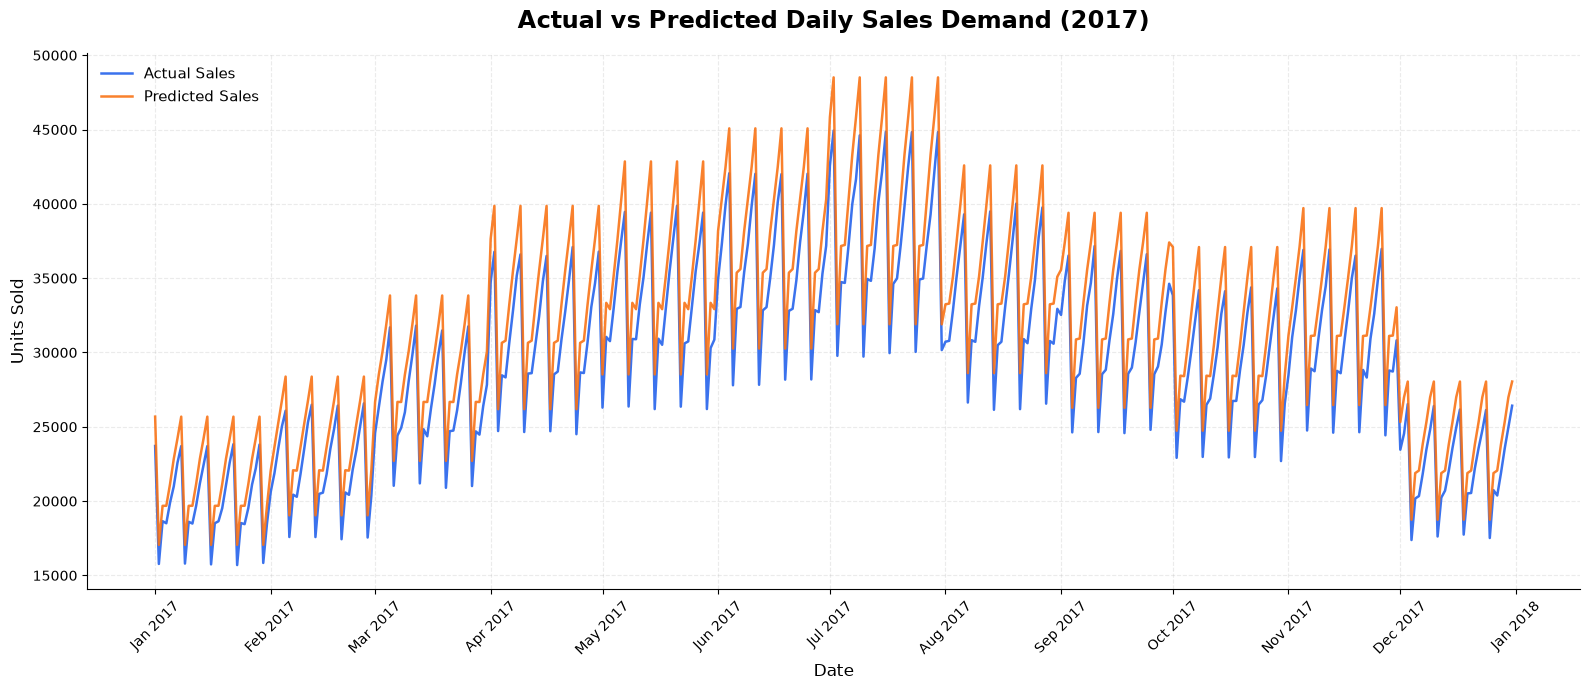

========== FORECAST CHART CREATED ==========
Chart File: ..\reports\figures\actual_vs_predicted_sales_2017.png
File Exists: True
========== CHART COMPLETE ==========


In [60]:
# Step 7.13.1 - Actual vs Predicted Daily Sales

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# Create output directory
figure_path = Path("../reports/figures")
figure_path.mkdir(parents=True, exist_ok=True)

# Create figure
fig, ax = plt.subplots(figsize=(16, 7))

# Actual daily demand
ax.plot(
    saved_forecast_df["date"],
    saved_forecast_df["Actual_Units"],
    label="Actual Sales",
    color="#2563EB",
    linewidth=1.8,
    alpha=0.9
)

# Predicted daily demand
ax.plot(
    saved_forecast_df["date"],
    saved_forecast_df["Predicted_Units"],
    label="Predicted Sales",
    color="#F97316",
    linewidth=1.8,
    alpha=0.9
)

# Title and labels
ax.set_title(
    "Actual vs Predicted Daily Sales Demand (2017)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Units Sold", fontsize=12)

# Date formatting
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)

# Chart styling
ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    loc="upper left",
    fontsize=11,
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save chart
chart_output_path = (
    figure_path / "actual_vs_predicted_sales_2017.png"
)

plt.savefig(
    chart_output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== FORECAST CHART CREATED ==========")
print("Chart File:", chart_output_path)
print("File Exists:", chart_output_path.exists())
print("========== CHART COMPLETE ==========")

In [61]:
# Step 7.13.1 - Chart Validation

print("========== FORECAST CHART VALIDATION ==========")

print(
    "Chart File Exists:",
    chart_output_path.exists()
)

print(
    "Chart File Not Empty:",
    chart_output_path.stat().st_size > 0
)

print(
    "365 Dates Available:",
    len(saved_forecast_df) == 365
)

print(
    "Actual Values Available:",
    saved_forecast_df["Actual_Units"].notna().all()
)

print(
    "Predicted Values Available:",
    saved_forecast_df["Predicted_Units"].notna().all()
)

print("========== VALIDATION COMPLETE ==========")

========== FORECAST CHART VALIDATION ==========
Chart File Exists: True
Chart File Not Empty: True
365 Dates Available: True
Actual Values Available: True
Predicted Values Available: True
========== VALIDATION COMPLETE ==========


### 13.2 Monthly Actual vs Predicted Sales

**Objective:** Compare monthly actual and predicted sales
for the 2017 test period.

**Visualization:** Grouped Bar Chart

**X-Axis:** Month

**Y-Axis:** Total Units Sold

**Purpose:** Analyze monthly forecasting performance
and identify demand overestimation or underestimation.

In [64]:
# Step 7.13.2 - Monthly Forecast Comparison

import pandas as pd
import numpy as np

monthly_forecast_df = (
    saved_forecast_df
    .groupby("Month", as_index=False)
    .agg(
        Actual_Units=("Actual_Units", "sum"),
        Predicted_Units=("Predicted_Units", "sum")
    )
)

# Add month names
import calendar

monthly_forecast_df["Month_Name"] = (
    monthly_forecast_df["Month"]
    .map(lambda month: calendar.month_abbr[int(month)])
)

# Monthly forecast error
monthly_forecast_df["Forecast_Error"] = (
    monthly_forecast_df["Actual_Units"]
    - monthly_forecast_df["Predicted_Units"]
)

# Absolute monthly forecast error
monthly_forecast_df["Absolute_Error"] = (
    monthly_forecast_df["Forecast_Error"].abs()
)

print("========== MONTHLY FORECAST COMPARISON ==========")

print("Total Months:", len(monthly_forecast_df))

display(
    monthly_forecast_df.style.format({
        "Actual_Units": "{:,.0f}",
        "Predicted_Units": "{:,.2f}",
        "Forecast_Error": "{:,.2f}",
        "Absolute_Error": "{:,.2f}"
    })
)

print("========== MONTHLY DATA READY ==========")

========== MONTHLY FORECAST COMPARISON ==========
Total Months: 12


,Month,Actual_Units,Predicted_Units,Month_Name,Forecast_Error,Absolute_Error
0,1,"617,306","663,713.71",Jan,"-46,407.71","46,407.71"
1,2,"621,369","668,744.03",Feb,"-47,375.03","47,375.03"
2,3,"822,667","886,704.42",Mar,"-64,037.42","64,037.42"
3,4,"938,862","1,013,077.93",Apr,"-74,215.93","74,215.93"
4,5,"1,020,686","1,097,054.38",May,"-76,368.38","76,368.38"
5,6,"1,064,624","1,147,567.53",Jun,"-82,943.53","82,943.53"
6,7,"1,171,393","1,263,181.24",Jul,"-91,788.24","91,788.24"
7,8,"1,026,403","1,102,813.80",Aug,"-76,410.80","76,410.80"
8,9,"935,263","1,008,267.75",Sep,"-73,004.75","73,004.75"
9,10,"891,160","958,260.43",Oct,"-67,100.43","67,100.43"


========== MONTHLY DATA READY ==========


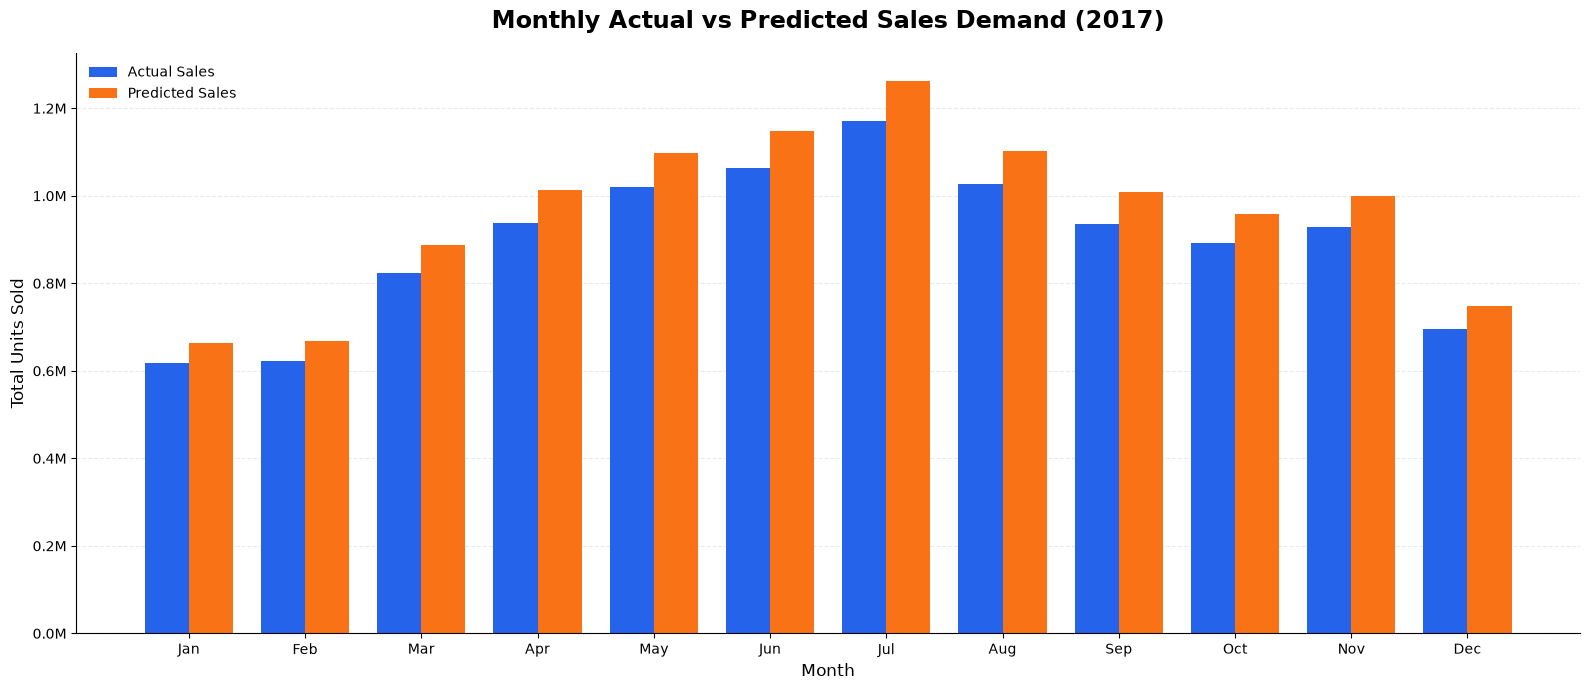

========== MONTHLY CHART CREATED ==========
Chart File: ..\reports\figures\monthly_actual_vs_predicted_2017.png
File Exists: True
========== CHART COMPLETE ==========


In [65]:
# Step 7.13.2 - Monthly Actual vs Predicted Chart

import matplotlib.pyplot as plt
from pathlib import Path

months = monthly_forecast_df["Month_Name"]

actual_sales = monthly_forecast_df["Actual_Units"]
predicted_sales = monthly_forecast_df["Predicted_Units"]

x = np.arange(len(months))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(16, 7))

# Actual sales bars
ax.bar(
    x - bar_width / 2,
    actual_sales,
    width=bar_width,
    label="Actual Sales",
    color="#2563EB"
)

# Predicted sales bars
ax.bar(
    x + bar_width / 2,
    predicted_sales,
    width=bar_width,
    label="Predicted Sales",
    color="#F97316"
)

ax.set_title(
    "Monthly Actual vs Predicted Sales Demand (2017)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(months)

# Display y-axis values in millions
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f}M")
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.legend(
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

monthly_chart_path = (
    Path("../reports/figures")
    / "monthly_actual_vs_predicted_2017.png"
)

plt.savefig(
    monthly_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== MONTHLY CHART CREATED ==========")

print("Chart File:", monthly_chart_path)
print("File Exists:", monthly_chart_path.exists())

print("========== CHART COMPLETE ==========")

In [66]:
# Step 7.13.2 - Monthly Chart Validation

print("========== MONTHLY CHART VALIDATION ==========")

print(
    "12 Months Available:",
    len(monthly_forecast_df) == 12
)

print(
    "Months in Correct Order:",
    monthly_forecast_df["Month"].tolist()
    == list(range(1, 13))
)

print(
    "Actual Sales Total Preserved:",
    np.isclose(
        monthly_forecast_df["Actual_Units"].sum(),
        saved_forecast_df["Actual_Units"].sum()
    )
)

print(
    "Predicted Sales Total Preserved:",
    np.isclose(
        monthly_forecast_df["Predicted_Units"].sum(),
        saved_forecast_df["Predicted_Units"].sum()
    )
)

print(
    "No Missing Monthly Values:",
    monthly_forecast_df.isna().sum().sum() == 0
)

print(
    "Chart File Exists:",
    monthly_chart_path.exists()
)

print(
    "Chart File Not Empty:",
    monthly_chart_path.exists()
    and monthly_chart_path.stat().st_size > 0
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY CHART VALIDATION ==========
12 Months Available: True
Months in Correct Order: True
Actual Sales Total Preserved: True
Predicted Sales Total Preserved: True
No Missing Monthly Values: True
Chart File Exists: True
Chart File Not Empty: True
========== VALIDATION COMPLETE ==========


### 13.3 Monthly Forecast Error Analysis

**Objective:** Analyze monthly forecast errors for 2017.

**Metrics:**
- Forecast Error (Actual - Predicted)
- Absolute Forecast Error
- Monthly Absolute Percentage Error

**Purpose:** Identify months with the highest and lowest
forecasting errors and detect systematic forecast bias.

In [67]:
# Step 7.13.3 - Monthly Forecast Error Analysis

import pandas as pd
import numpy as np

monthly_error_df = monthly_forecast_df.copy()

# Monthly percentage error based on net monthly difference
monthly_error_df["Monthly_Error_Percent"] = (
    monthly_error_df["Absolute_Error"]
    / monthly_error_df["Actual_Units"]
) * 100

# Determine forecast direction
monthly_error_df["Forecast_Direction"] = np.where(
    monthly_error_df["Forecast_Error"] < 0,
    "Overprediction",
    np.where(
        monthly_error_df["Forecast_Error"] > 0,
        "Underprediction",
        "Exact Prediction"
    )
)

# Sort by largest absolute error
monthly_error_ranking = (
    monthly_error_df
    .sort_values("Absolute_Error", ascending=False)
    .reset_index(drop=True)
)

print("========== MONTHLY FORECAST ERROR ANALYSIS ==========")

display(
    monthly_error_ranking[
        [
            "Month_Name",
            "Actual_Units",
            "Predicted_Units",
            "Forecast_Error",
            "Absolute_Error",
            "Monthly_Error_Percent",
            "Forecast_Direction"
        ]
    ].style.format({
        "Actual_Units": "{:,.0f}",
        "Predicted_Units": "{:,.2f}",
        "Forecast_Error": "{:,.2f}",
        "Absolute_Error": "{:,.2f}",
        "Monthly_Error_Percent": "{:.2f}%"
    })
)

print("========== ERROR ANALYSIS COMPLETE ==========")

========== MONTHLY FORECAST ERROR ANALYSIS ==========


,Month_Name,Actual_Units,Predicted_Units,Forecast_Error,Absolute_Error,Monthly_Error_Percent,Forecast_Direction
0,Jul,"1,171,393","1,263,181.24","-91,788.24","91,788.24",7.84%,Overprediction
1,Jun,"1,064,624","1,147,567.53","-82,943.53","82,943.53",7.79%,Overprediction
2,Aug,"1,026,403","1,102,813.80","-76,410.80","76,410.80",7.44%,Overprediction
3,May,"1,020,686","1,097,054.38","-76,368.38","76,368.38",7.48%,Overprediction
4,Apr,"938,862","1,013,077.93","-74,215.93","74,215.93",7.90%,Overprediction
5,Sep,"935,263","1,008,267.75","-73,004.75","73,004.75",7.81%,Overprediction
6,Nov,"928,837","998,900.00","-70,063.00","70,063.00",7.54%,Overprediction
7,Oct,"891,160","958,260.43","-67,100.43","67,100.43",7.53%,Overprediction
8,Mar,"822,667","886,704.42","-64,037.42","64,037.42",7.78%,Overprediction
9,Dec,"695,170","747,820.28","-52,650.28","52,650.28",7.57%,Overprediction


========== ERROR ANALYSIS COMPLETE ==========


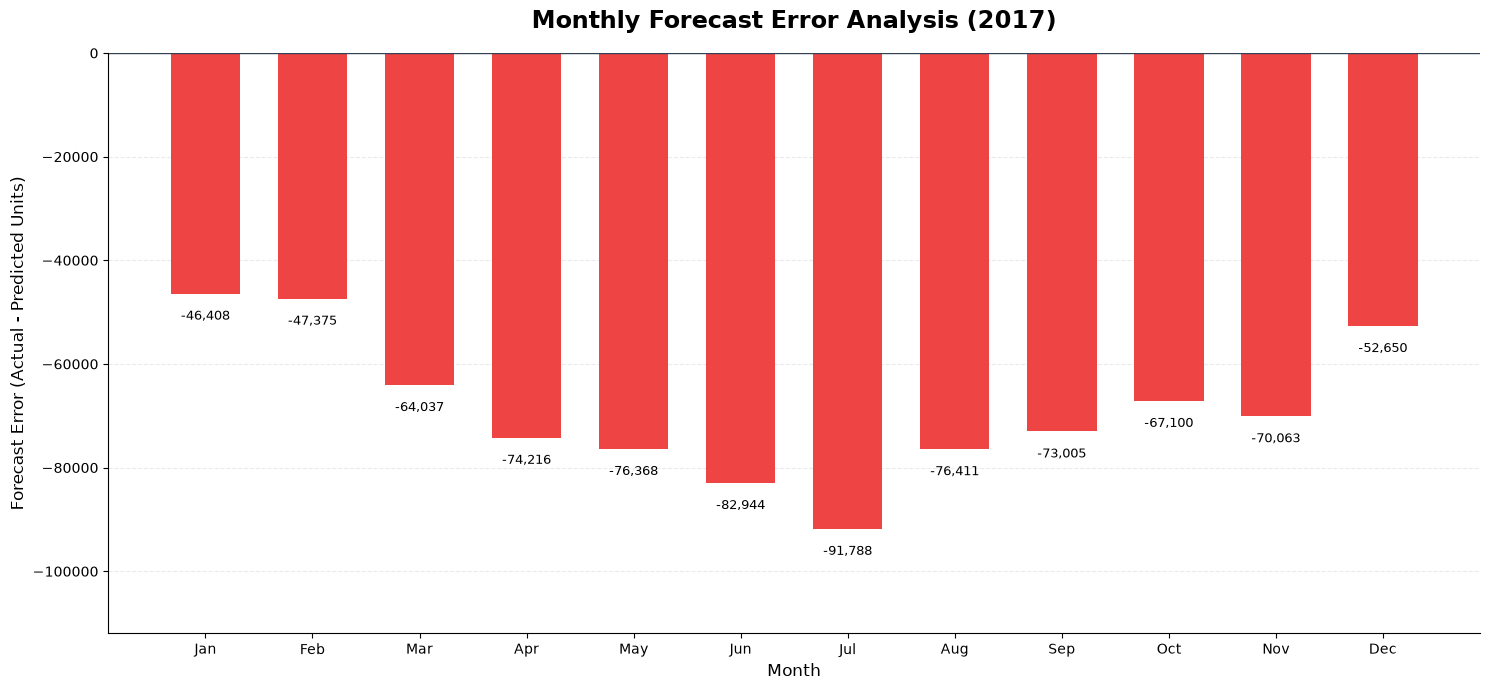

========== MONTHLY ERROR CHART CREATED ==========
Chart File: ..\reports\figures\monthly_forecast_error_2017.png
File Exists: True
========== CHART COMPLETE ==========


In [68]:
# Step 7.13.3 - Monthly Forecast Error Chart

import matplotlib.pyplot as plt
from pathlib import Path

# Keep chronological month order
monthly_error_chart_df = (
    monthly_error_df
    .sort_values("Month")
)

fig, ax = plt.subplots(figsize=(15, 7))

colors = [
    "#EF4444" if error < 0 else "#16A34A"
    for error in monthly_error_chart_df["Forecast_Error"]
]

bars = ax.bar(
    monthly_error_chart_df["Month_Name"],
    monthly_error_chart_df["Forecast_Error"],
    color=colors,
    width=0.65
)

ax.axhline(
    y=0,
    color="#334155",
    linewidth=1
)

ax.set_title(
    "Monthly Forecast Error Analysis (2017)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel(
    "Forecast Error (Actual - Predicted Units)",
    fontsize=12
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Display error values
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(0, -12 if height < 0 else 5),
        textcoords="offset points",
        ha="center",
        va="top" if height < 0 else "bottom",
        fontsize=9
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Extra room for negative value labels
ax.margins(y=0.22)

plt.tight_layout()

monthly_error_chart_path = (
    Path("../reports/figures")
    / "monthly_forecast_error_2017.png"
)

plt.savefig(
    monthly_error_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== MONTHLY ERROR CHART CREATED ==========")

print("Chart File:", monthly_error_chart_path)
print("File Exists:", monthly_error_chart_path.exists())

print("========== CHART COMPLETE ==========")

In [69]:
# Step 7.13.3 - Monthly Error Validation

print("========== MONTHLY ERROR VALIDATION ==========")

print(
    "12 Months Available:",
    len(monthly_error_df) == 12
)

print(
    "No Missing Error Values:",
    monthly_error_df[
        [
            "Forecast_Error",
            "Absolute_Error",
            "Monthly_Error_Percent"
        ]
    ].isna().sum().sum() == 0
)

print(
    "Absolute Errors Correct:",
    np.allclose(
        monthly_error_df["Absolute_Error"],
        np.abs(monthly_error_df["Forecast_Error"])
    )
)

print(
    "Percentage Errors Non-Negative:",
    (monthly_error_df["Monthly_Error_Percent"] >= 0).all()
)

print(
    "All Months Overpredicted:",
    (
        monthly_error_df["Forecast_Direction"]
        == "Overprediction"
    ).all()
)

print(
    "Monthly Errors Sum to Daily Errors:",
    np.isclose(
        monthly_error_df["Forecast_Error"].sum(),
        saved_forecast_df["Error"].sum()
    )
)

print(
    "Chart File Exists:",
    monthly_error_chart_path.exists()
)

print(
    "Chart File Not Empty:",
    monthly_error_chart_path.exists()
    and monthly_error_chart_path.stat().st_size > 0
)

print("========== VALIDATION COMPLETE ==========")

========== MONTHLY ERROR VALIDATION ==========
12 Months Available: True
No Missing Error Values: True
Absolute Errors Correct: True
Percentage Errors Non-Negative: True
All Months Overpredicted: True
Monthly Errors Sum to Daily Errors: True
Chart File Exists: True
Chart File Not Empty: True
========== VALIDATION COMPLETE ==========


### 13.4 Daily Forecast Error Distribution

**Objective:** Analyze the distribution of daily
forecast errors for the 2017 test period.

**Visualization:** Histogram

**X-Axis:** Forecast Error (Actual - Predicted)

**Y-Axis:** Number of Days

**Purpose:** Understand forecasting bias, error
variability, and daily prediction consistency.

In [70]:
# Step 7.13.4 - Daily Forecast Error Statistics

import numpy as np
import pandas as pd

daily_errors = saved_forecast_df["Error"]

daily_error_summary = pd.DataFrame({
    "Metric": [
        "Total Forecast Days",
        "Mean Forecast Error",
        "Median Forecast Error",
        "Minimum Forecast Error",
        "Maximum Forecast Error",
        "Standard Deviation",
        "Overpredicted Days",
        "Underpredicted Days",
        "Exact Prediction Days"
    ],
    "Value": [
        len(daily_errors),
        daily_errors.mean(),
        daily_errors.median(),
        daily_errors.min(),
        daily_errors.max(),
        daily_errors.std(),
        (daily_errors < 0).sum(),
        (daily_errors > 0).sum(),
        (daily_errors == 0).sum()
    ]
})

print("========== DAILY FORECAST ERROR STATISTICS ==========")

display(
    daily_error_summary.style.format({
        "Value": "{:,.2f}"
    })
)

print("========== ERROR STATISTICS COMPLETE ==========")

========== DAILY FORECAST ERROR STATISTICS ==========


,Metric,Value
0,Total Forecast Days,365.00
1,Mean Forecast Error,"-2,253.06"
2,Median Forecast Error,"-2,197.37"
3,Minimum Forecast Error,"-4,176.50"
4,Maximum Forecast Error,"-1,000.80"
5,Standard Deviation,587.18
6,Overpredicted Days,365.00
7,Underpredicted Days,0.00
8,Exact Prediction Days,0.00


========== ERROR STATISTICS COMPLETE ==========


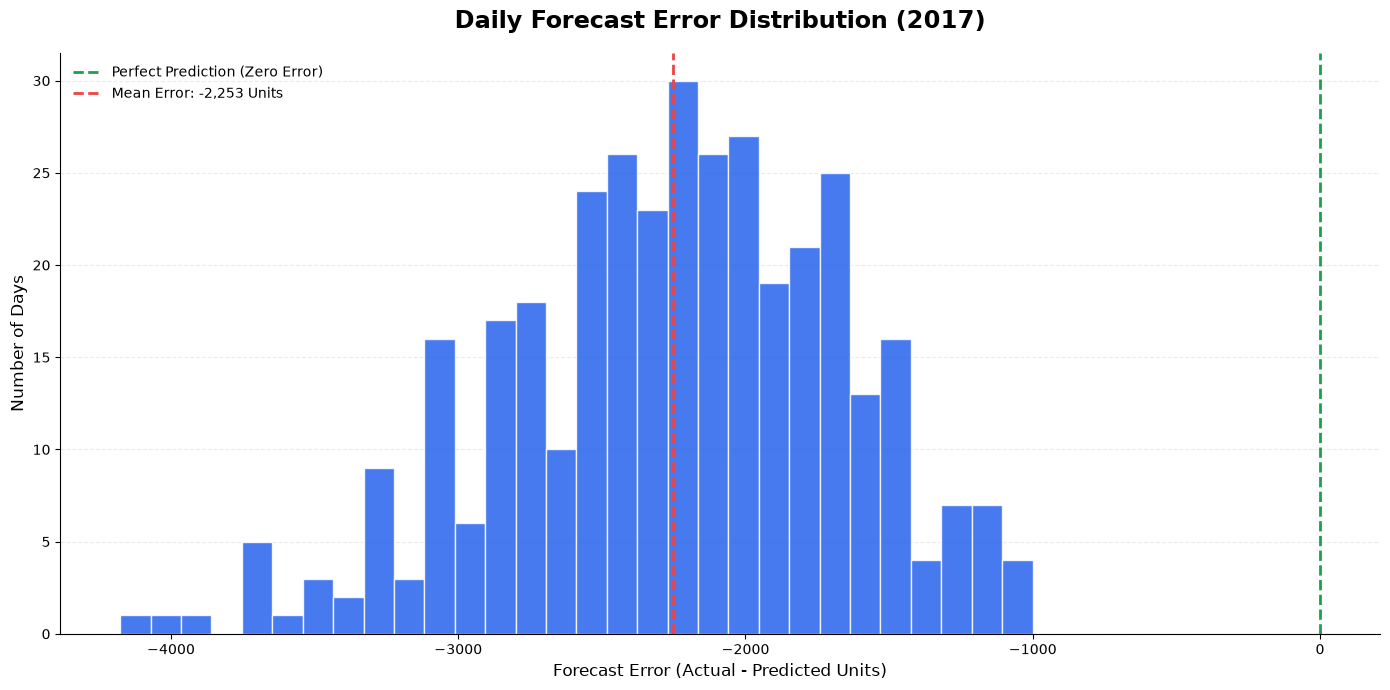

========== ERROR DISTRIBUTION CHART CREATED ==========
Chart File: ..\reports\figures\daily_forecast_error_distribution_2017.png
File Exists: True
========== CHART COMPLETE ==========


In [71]:
# Step 7.13.4 - Daily Forecast Error Histogram

import matplotlib.pyplot as plt
from pathlib import Path

fig, ax = plt.subplots(figsize=(14, 7))

ax.hist(
    daily_errors,
    bins=30,
    color="#2563EB",
    edgecolor="white",
    alpha=0.85
)

# Zero-error reference
ax.axvline(
    x=0,
    color="#16A34A",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction (Zero Error)"
)

# Mean-error reference
ax.axvline(
    x=daily_errors.mean(),
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label=f"Mean Error: {daily_errors.mean():,.0f} Units"
)

ax.set_title(
    "Daily Forecast Error Distribution (2017)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Forecast Error (Actual - Predicted Units)",
    fontsize=12
)

ax.set_ylabel(
    "Number of Days",
    fontsize=12
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.legend(
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

daily_error_chart_path = (
    Path("../reports/figures")
    / "daily_forecast_error_distribution_2017.png"
)

plt.savefig(
    daily_error_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== ERROR DISTRIBUTION CHART CREATED ==========")
print("Chart File:", daily_error_chart_path)
print("File Exists:", daily_error_chart_path.exists())
print("========== CHART COMPLETE ==========")

In [72]:
# Step 7.13.4 - Error Distribution Validation

print("========== ERROR DISTRIBUTION VALIDATION ==========")

print(
    "365 Daily Errors:",
    len(daily_errors) == 365
)

print(
    "No Missing Errors:",
    daily_errors.isna().sum() == 0
)

print(
    "All Errors Finite:",
    np.isfinite(daily_errors.to_numpy()).all()
)

print(
    "Mean Error Matches Test Bias:",
    np.isclose(
        daily_errors.mean(),
        final_test_bias
    )
)

print(
    "Daily Error Counts Match:",
    (
        (daily_errors < 0).sum()
        + (daily_errors > 0).sum()
        + (daily_errors == 0).sum()
    ) == 365
)

print(
    "Chart File Exists:",
    daily_error_chart_path.exists()
)

print(
    "Chart File Not Empty:",
    daily_error_chart_path.exists()
    and daily_error_chart_path.stat().st_size > 0
)

print("========== VALIDATION COMPLETE ==========")

========== ERROR DISTRIBUTION VALIDATION ==========
365 Daily Errors: True
No Missing Errors: True
All Errors Finite: True
Mean Error Matches Test Bias: True
Daily Error Counts Match: True
Chart File Exists: True
Chart File Not Empty: True
========== VALIDATION COMPLETE ==========


## 14. Final Forecasting Business Insights

**Objective:** Summarize final forecasting accuracy,
seasonal demand patterns, prediction bias, and
inventory planning implications.

**Evaluation Period:** 2017

**Selected Model:** Trend-Adjusted Seasonal Average

In [73]:
# Step 7.14 - Final Forecasting Business Insights

import pandas as pd
import numpy as np

# Identify highest and lowest demand months
highest_demand_month = monthly_forecast_df.loc[
    monthly_forecast_df["Actual_Units"].idxmax()
]

lowest_demand_month = monthly_forecast_df.loc[
    monthly_forecast_df["Actual_Units"].idxmin()
]

# Identify highest and lowest monthly forecast errors
highest_error_month = monthly_error_df.loc[
    monthly_error_df["Absolute_Error"].idxmax()
]

lowest_error_month = monthly_error_df.loc[
    monthly_error_df["Absolute_Error"].idxmin()
]

# Forecast direction counts
overpredicted_months = (
    monthly_error_df["Forecast_Direction"]
    == "Overprediction"
).sum()

underpredicted_months = (
    monthly_error_df["Forecast_Direction"]
    == "Underprediction"
).sum()

# Total annual demand
total_actual_demand = saved_forecast_df["Actual_Units"].sum()
total_predicted_demand = saved_forecast_df["Predicted_Units"].sum()

# Annual demand difference
annual_demand_difference = (
    total_predicted_demand - total_actual_demand
)

print("========== FINAL FORECASTING BUSINESS INSIGHTS ==========")

print("Selected Model:", selected_model)
print("Test Period: 2017")

print("\n--- Forecast Accuracy ---")
print("Final Test MAE:", round(final_test_mae, 2))
print("Final Test RMSE:", round(final_test_rmse, 2))
print("Final Test WAPE:", round(final_test_wape, 2), "%")

print("\n--- Annual Demand ---")
print("Actual Annual Demand:", f"{total_actual_demand:,.0f}")
print("Predicted Annual Demand:", f"{total_predicted_demand:,.2f}")
print("Annual Overforecast:", f"{annual_demand_difference:,.2f}")

print("\n--- Seasonal Demand ---")
print(
    "Highest Demand Month:",
    highest_demand_month["Month_Name"],
    f"{highest_demand_month['Actual_Units']:,.0f}"
)

print(
    "Lowest Demand Month:",
    lowest_demand_month["Month_Name"],
    f"{lowest_demand_month['Actual_Units']:,.0f}"
)

print("\n--- Forecast Error ---")
print(
    "Highest Absolute Error Month:",
    highest_error_month["Month_Name"],
    f"{highest_error_month['Absolute_Error']:,.2f}"
)

print(
    "Lowest Absolute Error Month:",
    lowest_error_month["Month_Name"],
    f"{lowest_error_month['Absolute_Error']:,.2f}"
)

print("Overpredicted Months:", overpredicted_months)
print("Underpredicted Months:", underpredicted_months)

print("========== INSIGHTS COMPLETE ==========")

========== FINAL FORECASTING BUSINESS INSIGHTS ==========
Selected Model: Trend-Adjusted Seasonal Average
Test Period: 2017

--- Forecast Accuracy ---
Final Test MAE: 2253.06
Final Test RMSE: 2328.11
Final Test WAPE: 7.66 %

--- Annual Demand ---
Actual Annual Demand: 10,733,740
Predicted Annual Demand: 11,556,105.48
Annual Overforecast: 822,365.48

--- Seasonal Demand ---
Highest Demand Month: Jul 1,171,393
Lowest Demand Month: Jan 617,306

--- Forecast Error ---
Highest Absolute Error Month: Jul 91,788.24
Lowest Absolute Error Month: Jan 46,407.71
Overpredicted Months: 12
Underpredicted Months: 0
========== INSIGHTS COMPLETE ==========


In [74]:
# Step 7.14 - Business Insights Validation

print("========== BUSINESS INSIGHTS VALIDATION ==========")

print(
    "Annual Actual Demand Preserved:",
    np.isclose(
        total_actual_demand,
        saved_forecast_df["Actual_Units"].sum()
    )
)

print(
    "Annual Predicted Demand Preserved:",
    np.isclose(
        total_predicted_demand,
        saved_forecast_df["Predicted_Units"].sum()
    )
)

print(
    "Annual Difference Correct:",
    np.isclose(
        annual_demand_difference,
        -saved_forecast_df["Error"].sum()
    )
)

print(
    "All Months Accounted For:",
    overpredicted_months
    + underpredicted_months
    + (monthly_error_df["Forecast_Direction"] == "Exact Prediction").sum()
    == 12
)

print(
    "Highest Demand Month Correct:",
    highest_demand_month["Actual_Units"]
    == monthly_forecast_df["Actual_Units"].max()
)

print(
    "Highest Error Month Correct:",
    highest_error_month["Absolute_Error"]
    == monthly_error_df["Absolute_Error"].max()
)

print(
    "Test Metrics Finite:",
    np.isfinite([
        final_test_mae,
        final_test_rmse,
        final_test_wape
    ]).all()
)

print("========== VALIDATION COMPLETE ==========")

========== BUSINESS INSIGHTS VALIDATION ==========
Annual Actual Demand Preserved: True
Annual Predicted Demand Preserved: True
Annual Difference Correct: True
All Months Accounted For: True
Highest Demand Month Correct: True
Highest Error Month Correct: True
Test Metrics Finite: True
========== VALIDATION COMPLETE ==========


## 15. Export Final Forecasting Business Insights

**Objective:** Export validated forecasting performance
and business insights for reporting and documentation.

**Model:** Trend-Adjusted Seasonal Average

**Evaluation Period:** 2017

**Output:** reports/forecast_business_insights.csv

In [75]:
# Step 7.15 - Prepare Business Insights Report

import pandas as pd
import numpy as np

business_insights = [
    {
        "Category": "Model Performance",
        "Metric": "Selected Forecasting Model",
        "Value": selected_model,
        "Unit": "Model"
    },
    {
        "Category": "Model Performance",
        "Metric": "Final Test MAE",
        "Value": round(final_test_mae, 2),
        "Unit": "Units"
    },
    {
        "Category": "Model Performance",
        "Metric": "Final Test RMSE",
        "Value": round(final_test_rmse, 2),
        "Unit": "Units"
    },
    {
        "Category": "Model Performance",
        "Metric": "Final Test WAPE",
        "Value": round(final_test_wape, 2),
        "Unit": "Percent"
    },
    {
        "Category": "Annual Demand",
        "Metric": "Actual Annual Demand",
        "Value": round(total_actual_demand),
        "Unit": "Units"
    },
    {
        "Category": "Annual Demand",
        "Metric": "Predicted Annual Demand",
        "Value": round(total_predicted_demand, 2),
        "Unit": "Units"
    },
    {
        "Category": "Annual Demand",
        "Metric": "Annual Overforecast",
        "Value": round(annual_demand_difference, 2),
        "Unit": "Units"
    },
    {
        "Category": "Seasonal Demand",
        "Metric": "Highest Demand Month",
        "Value": highest_demand_month["Month_Name"],
        "Unit": "Month"
    },
    {
        "Category": "Seasonal Demand",
        "Metric": "Lowest Demand Month",
        "Value": lowest_demand_month["Month_Name"],
        "Unit": "Month"
    },
    {
        "Category": "Forecast Error",
        "Metric": "Highest Absolute Error Month",
        "Value": highest_error_month["Month_Name"],
        "Unit": "Month"
    },
    {
        "Category": "Forecast Error",
        "Metric": "Lowest Absolute Error Month",
        "Value": lowest_error_month["Month_Name"],
        "Unit": "Month"
    },
    {
        "Category": "Forecast Error",
        "Metric": "Overpredicted Months",
        "Value": int(overpredicted_months),
        "Unit": "Months"
    },
    {
        "Category": "Forecast Error",
        "Metric": "Underpredicted Months",
        "Value": int(underpredicted_months),
        "Unit": "Months"
    }
]

business_insights_df = pd.DataFrame(business_insights)

print("========== BUSINESS INSIGHTS REPORT ==========")

print("Total Insights:", len(business_insights_df))

display(business_insights_df)

print("========== REPORT PREPARED ==========")

========== BUSINESS INSIGHTS REPORT ==========
Total Insights: 13


,Category,Metric,Value,Unit
0,Model Performance,Selected Forecasting Model,Trend-Adjusted Seasonal Average,Model
1,Model Performance,Final Test MAE,2253.06,Units
2,Model Performance,Final Test RMSE,2328.11,Units
3,Model Performance,Final Test WAPE,7.66,Percent
4,Annual Demand,Actual Annual Demand,10733740,Units
5,Annual Demand,Predicted Annual Demand,11556105.48,Units
6,Annual Demand,Annual Overforecast,822365.48,Units
7,Seasonal Demand,Highest Demand Month,Jul,Month
8,Seasonal Demand,Lowest Demand Month,Jan,Month
9,Forecast Error,Highest Absolute Error Month,Jul,Month


========== REPORT PREPARED ==========


In [76]:
# Step 7.15 - Save Business Insights Report

from pathlib import Path

insights_output_path = Path(
    "../reports/forecast_business_insights.csv"
)

insights_output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

business_insights_df.to_csv(
    insights_output_path,
    index=False
)

saved_insights_df = pd.read_csv(
    insights_output_path,
    keep_default_na=False
)

print("========== BUSINESS INSIGHTS SAVED ==========")

print("File:", insights_output_path)
print("File Exists:", insights_output_path.exists())
print("Saved Rows:", len(saved_insights_df))
print("Saved Columns:", len(saved_insights_df.columns))

print("========== SAVE COMPLETE ==========")

========== BUSINESS INSIGHTS SAVED ==========
File: ..\reports\forecast_business_insights.csv
File Exists: True
Saved Rows: 13
Saved Columns: 4
========== SAVE COMPLETE ==========


In [77]:
# Step 7.15 - Business Insights Export Validation

print("========== INSIGHTS EXPORT VALIDATION ==========")

print(
    "13 Insights Available:",
    len(saved_insights_df) == 13
)

print(
    "4 Columns Available:",
    len(saved_insights_df.columns) == 4
)

print(
    "No Missing Values:",
    saved_insights_df.isna().sum().sum() == 0
    and not saved_insights_df.eq("").any().any()
)

print(
    "Metric Names Unique:",
    saved_insights_df["Metric"].is_unique
)

print(
    "All Insights Preserved:",
    saved_insights_df["Metric"].tolist()
    == business_insights_df["Metric"].tolist()
)

print(
    "Saved WAPE Correct:",
    np.isclose(
        float(
            saved_insights_df.loc[
                saved_insights_df["Metric"] == "Final Test WAPE",
                "Value"
            ].iloc[0]
        ),
        round(final_test_wape, 2)
    )
)

print(
    "File Exists:",
    insights_output_path.exists()
)

print(
    "File Not Empty:",
    insights_output_path.exists()
    and insights_output_path.stat().st_size > 0
)

print("========== VALIDATION COMPLETE ==========")

========== INSIGHTS EXPORT VALIDATION ==========
13 Insights Available: True
4 Columns Available: True
No Missing Values: True
Metric Names Unique: True
All Insights Preserved: True
Saved WAPE Correct: True
File Exists: True
File Not Empty: True
========== VALIDATION COMPLETE ==========
